<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVCQRF_IoTIntrusionDetection_Kavitha2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVC and Quantum Random Forest for network intrusion detection on UNSW-NB15: Kavitha et al. 2025, step by step

This notebook re-implements, runs and checks the experiments of

> Kavitha S. S., Dhanush Sagar M. D. and Deepak S., "Internet of Things Network Intrusion Detection System Using Quantum and Classical Machine Learning," *IET Quantum Communication* 6, e70020 (2025). https://doi.org/10.1049/qtc2.70020

**What the paper does.** It builds a network intrusion detection system (NIDS) for IoT traffic that separates *Normal* from *Attack* flows. A 1000-flow sample of the **UNSW-NB15** data set is reduced to 4 correlation-selected features, min-max scaled and compressed by PCA, then fed to four models: a classical support vector classifier (**CSVC**), a classical random forest (**CRF**), a quantum support vector classifier (**QSVC**, a quantum-kernel SVM built with Qiskit) and a quantum random forest (**QRF**, an ensemble of quantum decision trees). Quantum models are simulated on a classical computer. The paper first reports them "without optimiser" (accuracy 95.37 % for QSVC, 98 % for QRF against 96.44 % / 96.65 % for the classical models) and then "with optimiser" (COBYLA, `maxiter = 100`: 99.2 % for QSVC and 99.78 % for QRF). It also reports precision, recall, F1 and run time (Tables 1-3).

**What this notebook does.**

1. Downloads UNSW-NB15 from a public Hugging Face mirror and draws a 1000-flow sample with the paper's class mix (70 % Normal, 30 % Attack).
2. Selects 4 features by correlation with the label, min-max scales them, reduces them with PCA to 3 components (the paper's `PauliFeatureMap` has dimension 3) and rescales to rotation angles; every transform is fitted on the training split only.
3. Shows the real data: class counts and labelled 2-D scatter plots of the real flows (the dataset-exploration section).
4. Trains the classical CSVC and CRF baselines, a QSVC with a Qiskit fidelity quantum kernel, a quantum random forest whose tree nodes decide with that quantum kernel, and an "optimiser" variant in which the kernel is trained with COBYLA (`maxiter = 100`) and compared with L-BFGS-B and SPSA.
5. Draws every quantum circuit that is executed (the circuit-architecture section).
6. Repeats the comparison over several random draws of the 1000 flows (mean +- std) and prints a claim-by-claim comparison with the paper's Tables 1-3.

**How to run it.** Open it in Colab with the badge above, choose a **CPU** runtime and use *Runtime -> Run all*. No GPU, no IBM account and no data upload are needed. With `FAST_MODE = True` (a smaller sample and shorter optimiser budget) it finishes in about 8 to 15 minutes; the full run (the saved outputs) uses the paper's 1000 flows and `maxiter = 100` and takes about 20 minutes on an idle machine and up to an hour on a busy one. Colab may ask you to restart the session once after the install cell; if so, run all cells again.

**What you get at the end.** A table of accuracy, precision, recall, F1 and run time for CSVC, CRF, QSVC and QRF with and without the optimiser, next to the paper's numbers, with a verdict (reproduced / not reached / cannot be checked) for every claim, and a critical reading of what the paper does and does not show.

## The paper in one page

**Problem.** Detect malicious flows in IoT network traffic from unencrypted flow-header statistics only (so that no payload inspection is needed).

**Decision.** Binary: *Normal* versus *Attack*.

**Data.** UNSW-NB15 (Moustafa and Slay, MilCIS 2015), "from Kaggle". The paper reduces it to **1000 data points and 4 main features** chosen with a correlation matrix, says the sample has 70 % normal and 30 % abnormal flows, applies min-max scaling and **PCA**, and splits it into train and test data (text: 80:20; Fig. 3 caption: 700 training and 300 test samples).

**Models.** CSVC (RBF kernel, about 130 support vectors reported), CRF, QSVC (Qiskit `PauliFeatureMap`, dimension 3, one repetition, Pauli list "z, y, z"; `QSVC` from `qiskit_machine_learning`), and QRF (T quantum decision trees trained on bootstrap partitions, predictions averaged, eq. 7). Optimiser trials with `L_BFGS_B`, `SPSA` and `COBYLA` at `maxiter = 100`; COBYLA was the best. Simulation on the local machine and in IBM Quantum Lab, no noise.

**Claims we can test.**

| Id | Claim | Where |
|---|---|---|
| C1 | Accuracy (%) without optimiser: CSVC 96.44, CRF 96.65, QSVC 95.37, QRF 98 | Table 1 |
| C2 | Accuracy (%) with optimiser: QSVC 99.2, QRF 99.78 | Table 1 |
| C3 | Precision / recall / F1: CSVC 0.9734 / 0.9611 / 0.955, CRF 0.9622 / 0.9413 / 0.964, QSVC 0.9932 / 0.9845 / 0.9931, QRF 0.9873 / 0.9812 / 0.9867 | Table 2 |
| C4 | Optimised quantum models beat the classical ones; classical models plateau around 96 % | Sec. 4, Conclusion |
| C5 | The optimiser raises the accuracy of both quantum models | Table 1 |
| C6 | COBYLA is the best of L-BFGS-B, SPSA and COBYLA at `maxiter = 100` | Sec. 4 |
| C7 | The CSVC on 1000 samples and 4 features has about 130 support vectors (13 % of the data); QSVC generalises with fewer | Sec. 3.4.1, 4 |
| C8 | Classical models are faster than the locally simulated quantum models (4.26 s and 17.5 s against "200 m" and "128 m") | Table 2 |

The paper publishes no code and no data, and its "Data availability" and "Code availability" statements say "nothing to report".

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data set | UNSW-NB15 "from Kaggle" | The public Hugging Face mirror `research-simulation26/unsw-nb15-parquet` of the official training and testing partitions, concatenated (257,673 flows); this mirror is not the Kaggle upload, but holds the same 43 features and labels |
| Sample | 1000 points, 70 % normal / 30 % abnormal | 1000 flows drawn at random (seeded) with exactly that mix (`N_SAMPLES`, `NORMAL_FRACTION`); the real data set is about 36 % normal, so this is a re-balanced sample |
| Split | 80:20 in the text, 700/300 in the Fig. 3 caption | 80:20, stratified (`TEST_SIZE = 0.2`) |
| Feature selection | "4 main features using a correlation matrix" | The 4 numeric features with the highest absolute Pearson correlation with the label on the training split, skipping any feature that is correlated above 0.9 with one already chosen (`# CHOICE:`) |
| Scaling and PCA | min-max scaling and PCA | `MinMaxScaler` on the 4 features, `PCA(3)`, then `MinMaxScaler((0, pi))` with test angles clipped to [0, pi]; all fitted on the training split only |
| Qubits | feature map "dimension three" | 3 qubits, one PCA component per qubit |
| Feature map | `PauliFeatureMap`, reps 1, Paulis "z, y, z" | `pauli_feature_map(3, reps=1, paulis=["Z", "Y", "ZZ"])`; I read the third entry as `ZZ` because a single-qubit Pauli repeated twice would be redundant (`# CHOICE:`); default full entanglement |
| QSVC | `QSVC` of `qiskit_machine_learning` | `QSVC` with an exact statevector fidelity kernel, `C = 1` (default; the paper gives no `C`) |
| QRF | quantum decision trees, bagging, averaged probabilities (eq. 7), after Srikumar et al. 2024 | Trees whose nodes compare the quantum-kernel similarity of a sample to two exemplars of different classes, chosen by Gini gain; 30 trees, depth 8, bootstrap partitions (`# CHOICE:`; the paper gives no tree parameters) |
| "With optimiser" | COBYLA, `maxiter = 100`; the object that is optimised is not stated | A trainable quantum kernel: one trainable `RY(theta_i)` per qubit before the feature map, trained with `QuantumKernelTrainer` and the SVC dual loss, COBYLA `maxiter = 100`, starting from `theta = 0` (the untrained kernel). Both QSVC and QRF use the trained kernel (`# CHOICE:`). A variational classifier (feature map + `RealAmplitudes` ansatz trained with COBYLA) is added as an alternative reading of the paper's Fig. 9 |
| Classical baselines | CSVC (RBF), CRF on the 4 features | `SVC(rbf)` and `RandomForestClassifier(100)` on the 4 scaled features (paper-faithful), on the 3 PCA angles (identical to the quantum inputs) and on all numeric features (a ceiling) |
| Metrics | accuracy, precision, recall, F1, time | the same, attack = positive class, plus confusion matrices, mean +- std over seeds |
| Quantum back-end | simulator / IBM Quantum Lab | exact statevector simulation (kernel) and the Aer shot simulator (variational classifier); no noise, no real hardware |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc pyarrow huggingface_hub
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo (about 8-15 min); False: the paper's 1000 flows and maxiter = 100 (about 20 min on an idle 8-thread laptop CPU, up to an hour on a busy one)

SEED  = 42
SEEDS = [42, 43] if FAST_MODE else [42, 43, 44]        # random draws of the 1000 flows for the repeated-run study (the first is the main run)

# Data (paper: 1000 data points, 70 % normal / 30 % abnormal, 4 features, PCA, 80:20 split)
N_SAMPLES       = 400 if FAST_MODE else 1000           # CHOICE in FAST_MODE only: the paper uses 1000
NORMAL_FRACTION = 0.70
TEST_SIZE       = 0.20
N_SELECT        = 4        # features kept by the correlation filter
CORR_REDUNDANCY = 0.90     # CHOICE: skip a feature that correlates above this with one already chosen
N_QUBITS        = 3        # PCA components = qubits (the paper's PauliFeatureMap has dimension 3)

# Quantum kernel (paper: PauliFeatureMap, reps 1, Paulis z, y, z)
FM_REPS = 1
PAULIS  = ["Z", "Y", "ZZ"]  # CHOICE: third entry read as ZZ
SVC_C   = 1.0               # CHOICE: the paper gives no C

# Optimiser (paper: COBYLA, maxiter 100)
KERNEL_MAXITER = 25 if FAST_MODE else 100
KERNEL_TRAIN_N = None       # None: train the kernel on the whole training split; or an int to subsample
OPT_STUDY_TRAIN, OPT_STUDY_VAL = (100, 80) if FAST_MODE else (150, 150)   # optimiser comparison (L-BFGS-B, SPSA, COBYLA): training / validation flows
OPT_STUDY_MAXITER = 20 if FAST_MODE else 100

# Quantum random forest (CHOICE: the paper gives no tree parameters)
QRF_TREES, QRF_DEPTH, QRF_MIN_SPLIT, QRF_CANDIDATES = (15, 7, 4, 12) if FAST_MODE else (30, 8, 4, 16)

# Alternative reading of the optimiser: variational classifier (feature map + ansatz + COBYLA)
RUN_VQC     = True
VQC_N_TRAIN = 80 if FAST_MODE else 200
VQC_MAXITER = 25 if FAST_MODE else 100
SHOTS       = 1024
CEILING_N   = 5000 if FAST_MODE else 20000   # flows for the classical-ceiling check in Section 11 (not in the paper)

# Optional: real IBM hardware is not used by the paper's reported numbers; leave empty to skip
IBM_TOKEN = ""

DATA_DIR = "unsw_nb15"     # downloaded files are cached here (parquet files, 17 MB)
NOTEBOOK_T0 = __import__("time").time()
print("FAST_MODE =", FAST_MODE, "| flows", N_SAMPLES, "| seeds", SEEDS, "| kernel maxiter", KERNEL_MAXITER)

FAST_MODE = False | flows 1000 | seeds [42, 43, 44] | kernel maxiter 100


In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics.pairwise import rbf_kernel

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import pauli_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.algorithms import QSVC, VQC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel, TrainableFidelityStatevectorKernel
from qiskit_machine_learning.kernels.algorithms import QuantumKernelTrainer
from qiskit_machine_learning.utils.loss_functions import SVCLoss
from qiskit_machine_learning.optimizers import COBYLA, SPSA, L_BFGS_B

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
os.makedirs(DATA_DIR, exist_ok=True)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

# Hugging Face token: not needed for the public mirror used here; resolved only from the environment or Colab Secrets.
# Never type a token into a cell; on Colab store it under Settings > Secrets as HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. Data: UNSW-NB15

The paper collects IoT-style traffic as the **UNSW-NB15** data set (Moustafa and Slay, MilCIS 2015, UNSW Canberra): flows generated in the Cyber Range Lab of the Australian Centre for Cyber Security, described by 42 header-level statistics (durations, packet and byte counts, TTLs, loads, jitter, TCP window and round-trip times, connection-count features, protocol, service, state). Each flow has a binary `label` (0 = normal, 1 = attack) and an `attack_cat` with one of nine attack families (Fuzzers, Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms).

The paper names the official training set (175,341 records) and testing set (82,332 records) and then says it reduced everything to 1000 data points. This notebook downloads both official partitions from the public Hugging Face mirror `research-simulation26/unsw-nb15-parquet`, concatenates them (the 1000 points are drawn from the union, since the paper does not say which partition they came from), and removes flows with missing or infinite values. The two random TCP sequence bases `stcpb` and `dtcpb` are dropped (`# CHOICE:` identifier-like noise). Exact duplicate rows are **kept**: the public files carry no IP addresses, ports or timestamps, so identical rows are distinct flows. The three categorical columns (`proto`, `service`, `state`) are not used by the paper's correlation filter and are not used here either.

In [4]:
HF_REPO = "research-simulation26/unsw-nb15-parquet"   # training_set.parquet (175,341 rows), testing_set.parquet (82,332 rows)

def tidy(df):
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in ("proto", "service", "state"):
        df[c] = df[c].astype(str).str.strip()
    return df

def load_unsw():
    from huggingface_hub import hf_hub_download
    d = os.path.join(DATA_DIR, "main")
    tr = hf_hub_download(HF_REPO, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
    te = hf_hub_download(HF_REPO, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
    return tidy(pd.read_parquet(tr)), tidy(pd.read_parquet(te))

t0 = time.time()
raw_train, raw_test = load_unsw()
print(f"official partitions: training {raw_train.shape}, testing {raw_test.shape} ({time.time() - t0:.0f} s)")

DROP_COLS = ["stcpb", "dtcpb"]                              # CHOICE: random TCP sequence bases
CAT_COLS  = ["proto", "service", "state"]
ATTACKS   = ["Analysis", "Backdoor", "DoS", "Exploits", "Fuzzers", "Generic", "Reconnaissance", "Shellcode", "Worms"]
CATS      = ["Normal"] + ATTACKS

full = pd.concat([raw_train, raw_test], ignore_index=True).drop(columns=DROP_COLS + ["id"], errors="ignore")
n0 = len(full)
NUM_COLS = [c for c in full.columns if c not in CAT_COLS + ["attack_cat", "label"]]
full[NUM_COLS] = full[NUM_COLS].apply(pd.to_numeric, errors="coerce")
full[["is_ftp_login", "ct_ftp_cmd", "ct_flw_http_mthd"]] = full[["is_ftp_login", "ct_ftp_cmd", "ct_flw_http_mthd"]].fillna(0)
full = full.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
full["label"] = full["label"].astype(int)
full["_rid"] = np.arange(len(full))        # row id, used only to keep the later "classical ceiling" pool disjoint from the 1000-flow sample
print(f"combined and cleaned: {n0:,} -> {len(full):,} flows | {len(NUM_COLS)} numeric features")
print("label (0 normal / 1 attack):", full["label"].value_counts().to_dict())

official partitions: training (175341, 44), testing (82332, 44) (8 s)


combined and cleaned: 257,673 -> 257,673 flows | 37 numeric features
label (0 normal / 1 attack): {1: 164673, 0: 93000}


## 2. Sampling, feature selection, scaling and PCA

The paper's preprocessing in order (Section 3.1): reduce the data to 1000 points and 4 features with a correlation matrix, standardise with min-max scaling, reduce with PCA, split 80:20. Here:

1. Draw `N_SAMPLES` flows with 70 % normal and 30 % attack (`NORMAL_FRACTION`), at random with a fixed seed.
2. Split 80:20, stratified by the label.
3. **On the training split only:** rank the numeric features by absolute Pearson correlation with the label and keep the top 4, skipping near-duplicates (`CORR_REDUNDANCY`); min-max scale them; fit a PCA with 3 components (one per qubit); rescale each component to $[0, \pi]$, the range of a rotation angle. Test flows go through the fitted transforms and the angles are clipped to $[0, \pi]$.

Three input sets come out, all from the same flows: the **4 scaled features** (what the paper's classical models read), the **3 PCA angles** (what the quantum models read) and **all numeric features** (a ceiling, not in the paper).

In [5]:
def select_features(tr, k=N_SELECT, redundancy=CORR_REDUNDANCY):
    # Correlation filter: top-k |corr(feature, label)| on the training split, skipping near-duplicate features. CHOICE (the paper only says "correlation matrix").
    X = tr[NUM_COLS].astype(float)
    corr = X.corrwith(tr["label"]).abs().fillna(0).sort_values(ascending=False)
    C = X.corr().abs()
    sel = []
    for f in corr.index:
        if all(C.loc[f, g] < redundancy for g in sel):
            sel.append(f)
        if len(sel) == k:
            break
    return sel, corr

def log1p_clip(X):
    return np.log1p(np.clip(X, 0, None))

def prepare(seed):
    n_norm = int(round(N_SAMPLES * NORMAL_FRACTION)); n_att = N_SAMPLES - n_norm
    s = pd.concat([full[full.label == 0].sample(n_norm, random_state=seed), full[full.label == 1].sample(n_att, random_state=seed)])
    s = s.sample(frac=1, random_state=seed).reset_index(drop=True)
    tr, te = train_test_split(s, test_size=TEST_SIZE, stratify=s["label"], random_state=seed)
    tr, te = tr.reset_index(drop=True), te.reset_index(drop=True)
    sel, corr = select_features(tr)
    mm4 = MinMaxScaler().fit(tr[sel])
    S4_tr, S4_te = mm4.transform(tr[sel]), mm4.transform(te[sel])                 # the paper's 4 scaled features
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(S4_tr)
    Z_tr, Z_te = pca.transform(S4_tr), pca.transform(S4_te)                       # raw PCA coordinates
    mmA = MinMaxScaler(feature_range=(0, np.pi)).fit(Z_tr)
    A_tr, A_te = mmA.transform(Z_tr), np.clip(mmA.transform(Z_te), 0, np.pi)      # angles in [0, pi]
    allsc = StandardScaler().fit(log1p_clip(tr[NUM_COLS].to_numpy(float)))        # all-features ceiling
    F_tr, F_te = allsc.transform(log1p_clip(tr[NUM_COLS].to_numpy(float))), allsc.transform(log1p_clip(te[NUM_COLS].to_numpy(float)))
    return dict(seed=seed, s=s, tr=tr, te=te, sel=sel, corr=corr, pca=pca, y_tr=tr["label"].to_numpy(), y_te=te["label"].to_numpy(),
                S4_tr=S4_tr, S4_te=S4_te, Z_tr=Z_tr, Z_te=Z_te, A_tr=A_tr, A_te=A_te, F_tr=F_tr, F_te=F_te)

D = prepare(SEED)
print(f"seed {SEED}: sample {len(D['s'])} flows -> train {len(D['tr'])}, test {len(D['te'])}")
print("train labels:", np.bincount(D["y_tr"]).tolist(), "| test labels:", np.bincount(D["y_te"]).tolist(), "(index 0 = normal, 1 = attack)")
print("selected features (|corr with label| on the training split):", {f: round(float(D["corr"][f]), 3) for f in D["sel"]})
print("PCA explained variance of the 3 components:", np.round(D["pca"].explained_variance_ratio_, 3), "-> total", f"{D['pca'].explained_variance_ratio_.sum():.1%}")

seed 42: sample 1000 flows -> train 800, test 200
train labels: [560, 240] | test labels: [140, 60] (index 0 = normal, 1 = attack)
selected features (|corr with label| on the training split): {'sttl': 0.537, 'ct_dst_sport_ltm': 0.49, 'ct_src_dport_ltm': 0.421, 'swin': 0.399}
PCA explained variance of the 3 components: [0.624 0.329 0.044] -> total 99.7%


## Dataset Exploration and Visualisation

Everything below shows the **real UNSW-NB15 flows** and their ground-truth labels. First the shape, the feature names and the original label values; then the class distributions of the full data and of the 1000-flow sample; then 2-D scatter plots of the real training flows coloured by their true class: the first PCA coordinates (PCA fitted on the training split), and the same points after the min-max scaling to angles in $[0, \pi]$ that the quantum feature map receives. The flows are coloured by attack family (multiclass labels kept) and by the binary label.

In [6]:
print("official training partition (raw):", raw_train.shape, "| official testing partition (raw):", raw_test.shape)
print("combined and cleaned data         :", full.shape)
print(f"\nnumeric features ({len(NUM_COLS)}): {NUM_COLS}")
print(f"categorical features (not used by the paper's correlation filter) = {CAT_COLS}")
print("\noriginal labels")
print("  label (0 normal / 1 attack):", full["label"].value_counts().to_dict())
print("  attack_cat                 :", full["attack_cat"].value_counts().to_dict())
print(f"\n1000-flow sample used here (seed {SEED}, N_SAMPLES = {N_SAMPLES}):")
print("  train label counts:", D["tr"]["label"].value_counts().to_dict(), "| test label counts:", D["te"]["label"].value_counts().to_dict())
print("  attack_cat in the sample:", D["s"]["attack_cat"].value_counts().to_dict())
print("\nselected features:", D["sel"])
display(D["tr"][D["sel"] + ["attack_cat", "label"]].head(5))
display(D["tr"][D["sel"]].describe().T[["mean", "std", "min", "max"]])

official training partition (raw): (175341, 44) | official testing partition (raw): (82332, 44)
combined and cleaned data         : (257673, 43)

numeric features (37): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sintpkt', 'dintpkt', 'sjit', 'djit', 'swin', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
categorical features (not used by the paper's correlation filter) = ['proto', 'service', 'state']

original labels
  label (0 normal / 1 attack): {1: 164673, 0: 93000}
  attack_cat                 : {'Normal': 93000, 'Generic': 58871, 'Exploits': 44525, 'Fuzzers': 24246, 'DoS': 16353, 'Reconnaissance': 13987, 'Analysis': 2677, 'Backdoor': 2329, 'Shellcode': 1511, 'Worms': 174}

1000-flow

,sttl,ct_dst_sport_ltm,ct_src_dport_ltm,swin,attack_cat,label
0,254,2,2,0,DoS,1
1,31,1,1,0,Normal,0
2,31,1,1,0,Normal,0
3,31,1,3,0,Normal,0
4,31,1,1,0,Normal,0


,mean,std,min,max
sttl,139.81500,109.929210,0.0,254.0
ct_dst_sport_ltm,2.68000,4.746922,1.0,46.0
ct_src_dport_ltm,3.69875,6.588038,1.0,51.0
swin,153.63750,124.870220,0.0,255.0


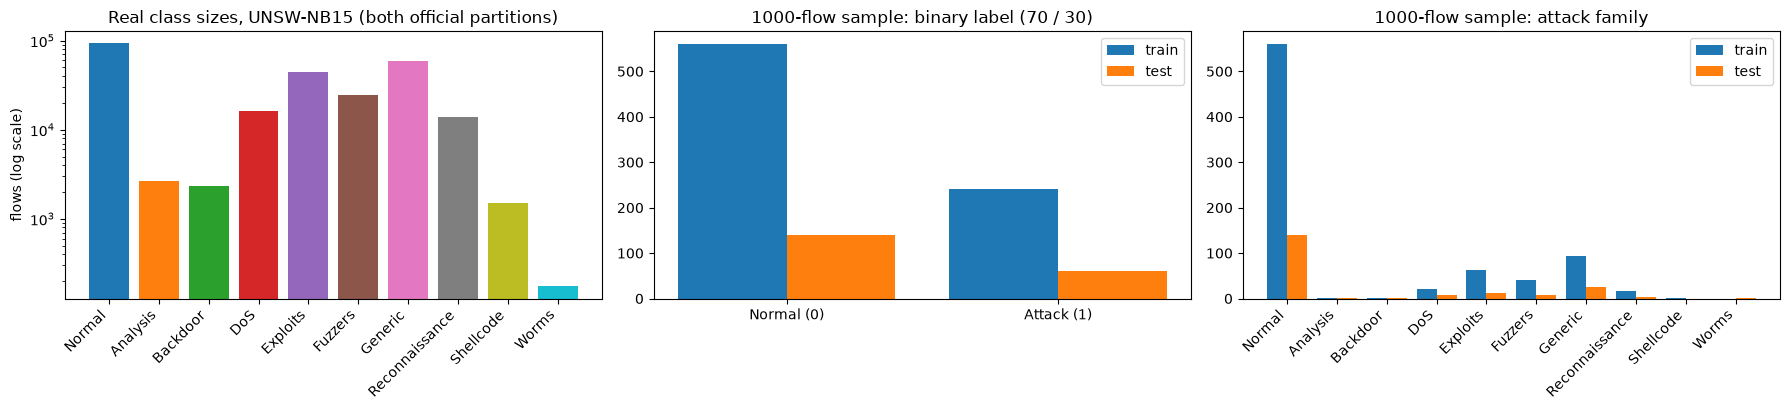

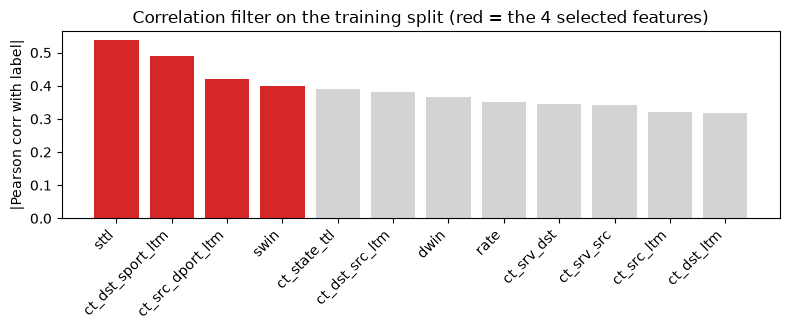

In [7]:
PAL = dict(zip(CATS, plt.cm.tab10(np.arange(10))))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
cnt = full["attack_cat"].value_counts().reindex(CATS)
ax[0].bar(range(10), cnt.values, color=[PAL[c] for c in CATS]); ax[0].set_yscale("log")
ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CATS, rotation=45, ha="right"); ax[0].set_ylabel("flows (log scale)")
ax[0].set_title("Real class sizes, UNSW-NB15 (both official partitions)")
w = 0.4; tr_c = D["tr"]["label"].value_counts().sort_index(); te_c = D["te"]["label"].value_counts().sort_index()
ax[1].bar(np.arange(2) - w / 2, tr_c.values, w, label="train", color="tab:blue"); ax[1].bar(np.arange(2) + w / 2, te_c.values, w, label="test", color="tab:orange")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Normal (0)", "Attack (1)"]); ax[1].legend(); ax[1].set_title("1000-flow sample: binary label (70 / 30)")
s_tr = D["tr"]["attack_cat"].value_counts().reindex(CATS).fillna(0); s_te = D["te"]["attack_cat"].value_counts().reindex(CATS).fillna(0)
ax[2].bar(np.arange(10) - w / 2, s_tr.values, w, label="train", color="tab:blue"); ax[2].bar(np.arange(10) + w / 2, s_te.values, w, label="test", color="tab:orange")
ax[2].set_xticks(range(10)); ax[2].set_xticklabels(CATS, rotation=45, ha="right"); ax[2].legend(); ax[2].set_title("1000-flow sample: attack family")
plt.tight_layout(); plt.show()

top = D["corr"].head(12)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(range(len(top)), top.values, color=["tab:red" if f in D["sel"] else "lightgray" for f in top.index])
ax.set_xticks(range(len(top))); ax.set_xticklabels(top.index, rotation=45, ha="right"); ax.set_ylabel("|Pearson corr with label|")
ax.set_title("Correlation filter on the training split (red = the 4 selected features)"); plt.tight_layout(); plt.show()

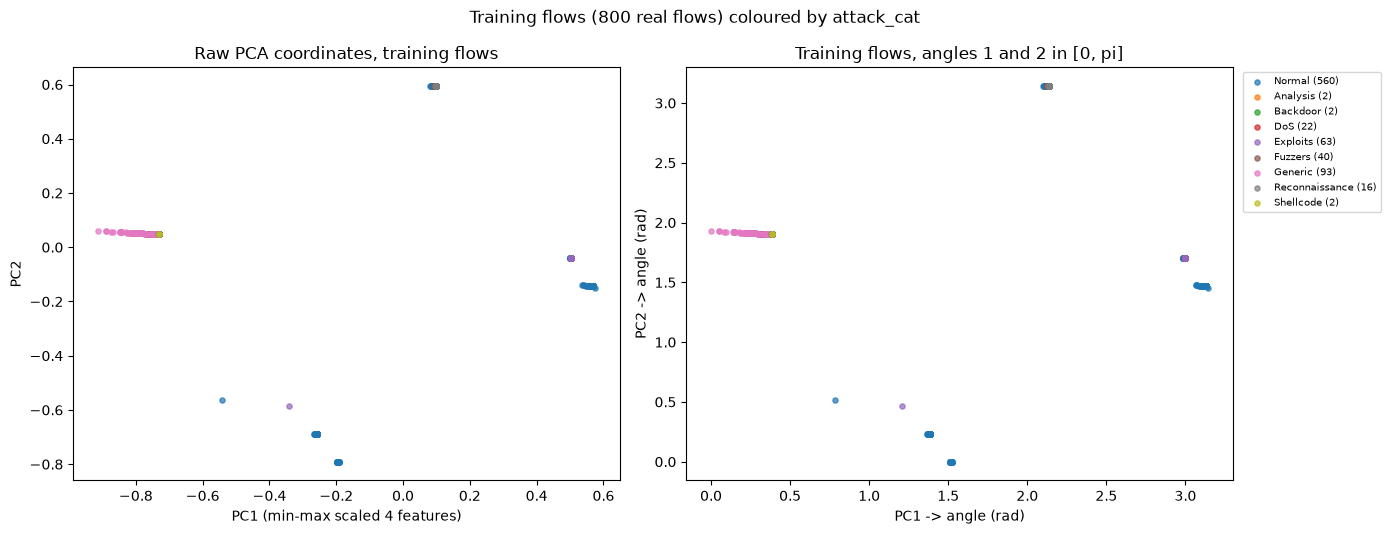

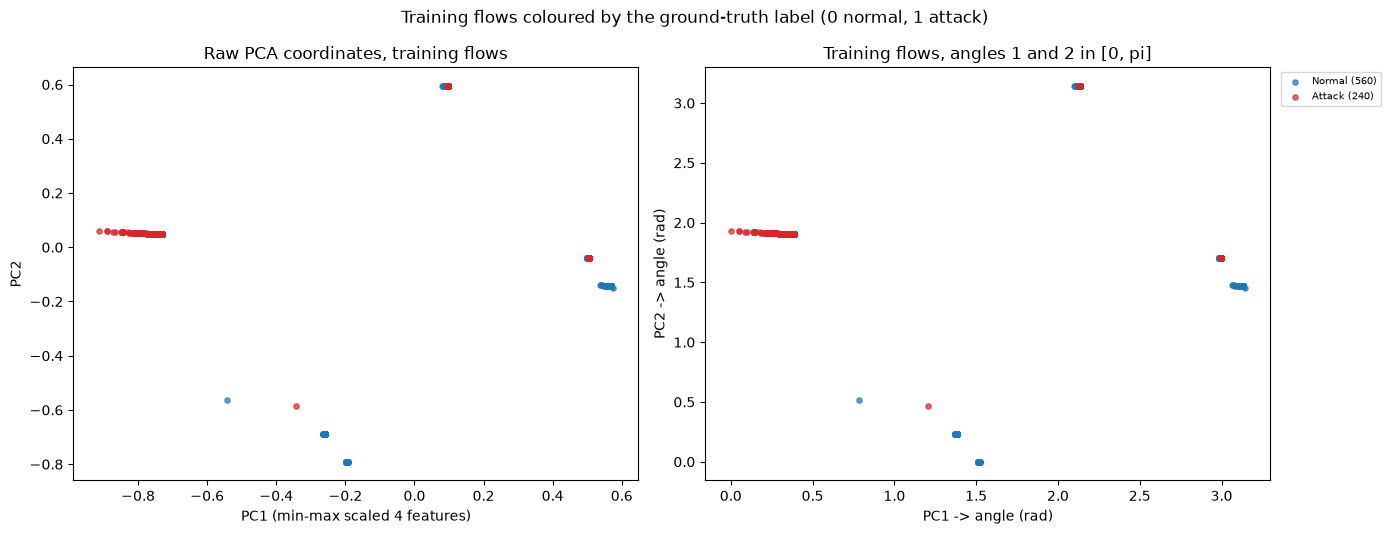

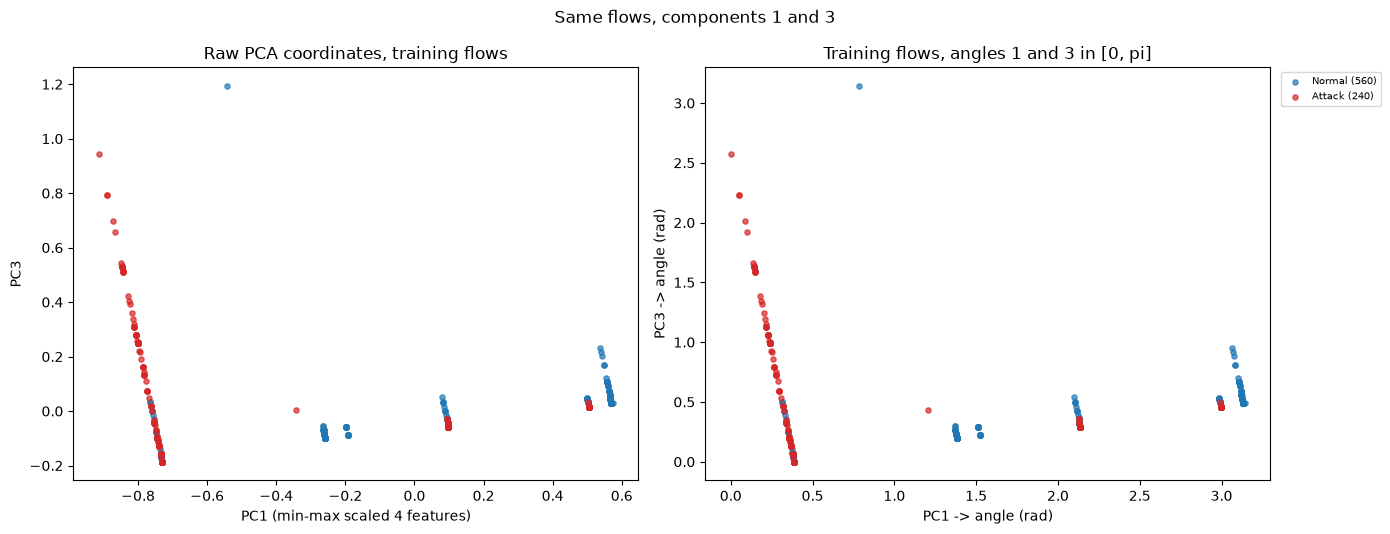

In [8]:
def scatter_pair(Z, A, labels, names, palette, title, dims=(0, 1)):
    # left: raw PCA coordinates, right: the same real flows as angles in [0, pi]; every point is one real flow
    i, j = dims
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
    for k, name in enumerate(names):
        m = labels == k
        if m.sum() == 0: continue
        ax[0].scatter(Z[m, i], Z[m, j], s=14, alpha=.7, color=palette[name], label=f"{name} ({m.sum()})")
        ax[1].scatter(A[m, i], A[m, j], s=14, alpha=.7, color=palette[name], label=f"{name} ({m.sum()})")
    ax[0].set_xlabel(f"PC{i+1} (min-max scaled 4 features)"); ax[0].set_ylabel(f"PC{j+1}"); ax[0].set_title("Raw PCA coordinates, training flows")
    ax[1].set_xlabel(f"PC{i+1} -> angle (rad)"); ax[1].set_ylabel(f"PC{j+1} -> angle (rad)"); ax[1].set_title(f"Training flows, angles {i+1} and {j+1} in [0, pi]")
    ax[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.suptitle(title); plt.tight_layout(); plt.show()

cat_idx = D["tr"]["attack_cat"].map({c: i for i, c in enumerate(CATS)}).to_numpy()
scatter_pair(D["Z_tr"], D["A_tr"], cat_idx, CATS, PAL, "Training flows (%d real flows) coloured by attack_cat" % len(D["tr"]))
BPAL = {"Normal": "tab:blue", "Attack": "tab:red"}
scatter_pair(D["Z_tr"], D["A_tr"], D["y_tr"], ["Normal", "Attack"], BPAL, "Training flows coloured by the ground-truth label (0 normal, 1 attack)")
scatter_pair(D["Z_tr"], D["A_tr"], D["y_tr"], ["Normal", "Attack"], BPAL, "Same flows, components 1 and 3", dims=(0, 2))

## 3. Classical baselines: CSVC and CRF

The paper's classical models are scikit-learn's `SVC` (RBF kernel) and `RandomForestClassifier`, trained on the 4 min-max scaled features. They are fitted here on exactly that input (the paper-faithful setting), on the **3 PCA angles that the quantum models receive** (identical inputs), and on all numeric features (a ceiling that shows how much the 4-feature reduction costs). Metrics follow equations 8-11 of the paper with **Attack as the positive class**; the time is the wall-clock time of fitting plus predicting.

In [9]:
def score(y, p):
    return dict(acc=100 * accuracy_score(y, p), prec=precision_score(y, p, zero_division=0), rec=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0), **dict(zip(["tn", "fp", "fn", "tp"], confusion_matrix(y, p, labels=[0, 1]).ravel().tolist())))

def timed_fit_predict(model, Xtr, ytr, Xte):
    t0 = time.time(); model.fit(Xtr, ytr); p = model.predict(Xte); return p, time.time() - t0

def run_classical(D, seed):
    out = {}
    for tag, (Xa, Xb) in {"4 features": (D["S4_tr"], D["S4_te"]), "3 PCA angles": (D["A_tr"], D["A_te"]), "all features": (D["F_tr"], D["F_te"])}.items():
        for name, model in {"CSVC": SVC(kernel="rbf", random_state=seed), "CRF": RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=2)}.items():
            p, t = timed_fit_predict(model, Xa, D["y_tr"], Xb)
            out[f"{name} ({tag})"] = dict(pred=p, time=t, model=model, **score(D["y_te"], p))
    return out

CL = run_classical(D, SEED)
cl_df = pd.DataFrame({k: {m: v[m] for m in ["acc", "prec", "rec", "f1", "time"]} for k, v in CL.items()}).T.round(4)
display(cl_df)
svc4 = CL["CSVC (4 features)"]["model"]
print(f"CSVC on 4 features: {int(svc4.n_support_.sum())} support vectors = {svc4.n_support_.sum() / len(D['y_tr']):.1%} of the {len(D['y_tr'])} training flows (paper: about 130 = 13 % of 1000)")

,acc,prec,rec,f1,time
CSVC (4 features),88.5,0.8627,0.7333,0.7928,0.0256
CRF (4 features),91.5,0.8772,0.8333,0.8547,2.6053
CSVC (3 PCA angles),88.5,0.8627,0.7333,0.7928,0.0951
CRF (3 PCA angles),91.0,0.8621,0.8333,0.8475,1.7270
CSVC (all features),90.5,0.9020,0.7667,0.8288,0.1198
CRF (all features),95.0,0.9808,0.8500,0.9107,1.8908


CSVC on 4 features: 249 support vectors = 31.1% of the 800 training flows (paper: about 130 = 13 % of 1000)


## 4. Classical-to-quantum mapping and the quantum kernel

Each flow becomes a 3-qubit state $|\phi(x)\rangle = U_{\Phi}(x)|0\rangle^{\otimes 3}$ through Qiskit's `PauliFeatureMap` (dimension 3, one repetition, Paulis $Z$, $Y$ and $ZZ$; the paper's "z, y, z"). The **quantum kernel** is the state overlap

$$k(x, x') = |\langle \phi(x)|\phi(x')\rangle|^2,$$

the probability of measuring $|000\rangle$ after running $U_\Phi(x')^\dagger U_\Phi(x)$. A **QSVC** is an ordinary SVM that uses this kernel; the SVM optimisation stays classical. The kernel is computed *exactly* from statevectors (no shot noise, as in a noiseless simulation).

Qiskit's `FidelityStatevectorKernel` fills the Gram matrix with a Python double loop (about 30 s for 800 flows); the next cell keeps its maths and `_get_statevector_` but computes the Gram matrix with one matrix product, so that the optimiser in Section 7 can evaluate the kernel a hundred times. A check against Qiskit's own class follows.

In [10]:
def bound_states(kernel, X):
    # statevector of the feature-map circuit for every row (Qiskit's own code path), as an (n, 2**q) complex array
    return np.array([kernel._get_statevector(tuple(r)) for r in X])

class FastFidelityKernel(FidelityStatevectorKernel):
    # identical maths to FidelityStatevectorKernel, vectorised Gram matrix
    def _evaluate(self, x_vec, y_vec, is_symmetric):
        Sx = bound_states(self, x_vec); Sy = Sx if is_symmetric else bound_states(self, y_vec)
        return np.abs(np.conj(Sx) @ Sy.T) ** 2

class FastTrainableKernel(TrainableFidelityStatevectorKernel):
    def _evaluate(self, x_vec, y_vec, is_symmetric):
        nx = self._parameter_array(x_vec); ny = nx if is_symmetric else self._parameter_array(y_vec)
        Sx = bound_states(self, nx); Sy = Sx if is_symmetric else bound_states(self, ny)
        return np.abs(np.conj(Sx) @ Sy.T) ** 2

# CHOICE: PauliFeatureMap(3), reps 1, Paulis Z, Y, ZZ (paper: "z, y, z"), full entanglement (Qiskit default)
FEATURE_MAP = pauli_feature_map(N_QUBITS, reps=FM_REPS, paulis=PAULIS)
kernel_plain = FastFidelityKernel(feature_map=FEATURE_MAP)

# check against Qiskit's own (slow) kernel on 40 flows: same Gram matrix
chk = D["A_tr"][:40]; chk2 = D["A_tr"][40:60]
K_ref = FidelityStatevectorKernel(feature_map=FEATURE_MAP).evaluate(chk)
K_fast = kernel_plain.evaluate(chk)
assert np.allclose(K_ref, K_fast, atol=1e-10), "fast kernel differs from FidelityStatevectorKernel"
assert np.allclose(FidelityStatevectorKernel(feature_map=FEATURE_MAP).evaluate(chk, chk2), kernel_plain.evaluate(chk, chk2), atol=1e-10)
print("fast Gram matrix == qiskit FidelityStatevectorKernel (max abs diff %.1e)" % np.abs(K_ref - K_fast).max())
t0 = time.time(); K_demo = kernel_plain.evaluate(D["A_tr"]); print(f"Gram matrix of {len(D['A_tr'])} training flows in {time.time() - t0:.1f} s")
print("kernel values: min %.3f, mean off-diagonal %.3f, max off-diagonal %.3f" % (K_demo.min(), K_demo[~np.eye(len(K_demo), dtype=bool)].mean(), (K_demo - np.eye(len(K_demo))).max()))

fast Gram matrix == qiskit FidelityStatevectorKernel (max abs diff 1.6e-15)


Gram matrix of 800 training flows in 0.8 s
kernel values: min 0.000, mean off-diagonal 0.331, max off-diagonal 1.000


## Quantum Circuit Architecture

This section draws the circuits that the cells of this notebook actually build and run, with qubit count, depth and trainable-parameter count for each. The models are:

1. the **feature-map circuit** $U_\Phi(x)$ that every quantum model uses (QSVC and QRF, untrained);
2. the **kernel circuit** $U_\Phi(x')^\dagger U_\Phi(x)$ whose $|000\rangle$ probability is one kernel entry (checked against the kernel value used by the classifiers);
3. the **trainable kernel circuit** (one $R_Y(\theta_i)$ per qubit followed by the feature map) trained by COBYLA in Section 7; its drawing is shown after training with the learned angles;
4. the **variational classifier circuit** (feature map plus `RealAmplitudes` ansatz) of the alternative reading of the optimiser (Section 7b).

Circuit details that the paper omits (Paulis, entanglement pattern, ansatz, where the trainable angles sit, tree parameters) are chosen in this notebook and listed at the end of the section. The quantum random forest has no circuit of its own: each node decision reads two entries of the kernel Gram matrix, i.e. it runs the kernel circuit of item 2 on exemplar pairs.

PauliFeatureMap U(x) (paulis Z, Y, ZZ; reps 1): 3 qubits | depth 18 (decomposed to basic gates) | 3 parameters (data inputs, no trainable weights) | gates {'u': 30, 'cx': 6}


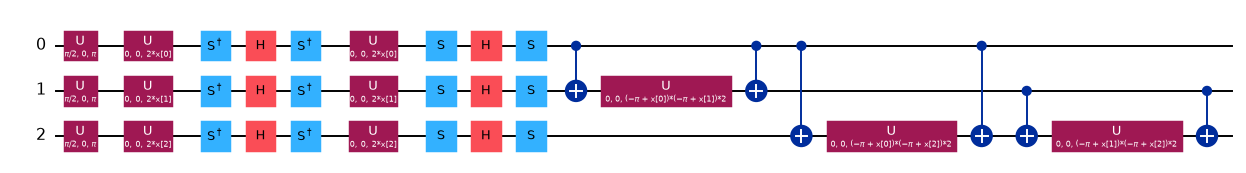

In [11]:
def describe(name, qc, extra=""):
    flat = qc.decompose(reps=3)
    ops = {k: v for k, v in flat.count_ops().items() if k != "barrier"}
    print(f"{name}: {qc.num_qubits} qubits | depth {flat.depth()} (decomposed to basic gates) | {qc.num_parameters} parameters {extra}| gates {ops}")

describe("PauliFeatureMap U(x) (paulis Z, Y, ZZ; reps 1)", FEATURE_MAP, "(data inputs, no trainable weights) ")
display(FEATURE_MAP.decompose().draw("mpl", fold=-1, scale=0.7))

Kernel circuit U(x')^dagger U(x) for two real training flows: 3 qubits | depth 36 (decomposed to basic gates) | 0 parameters (numbers bound) | gates {'u': 60, 'cx': 12}
P(|000>) after the kernel circuit = 0.009697 == kernel value 0.009697  ->  circuit and kernel agree


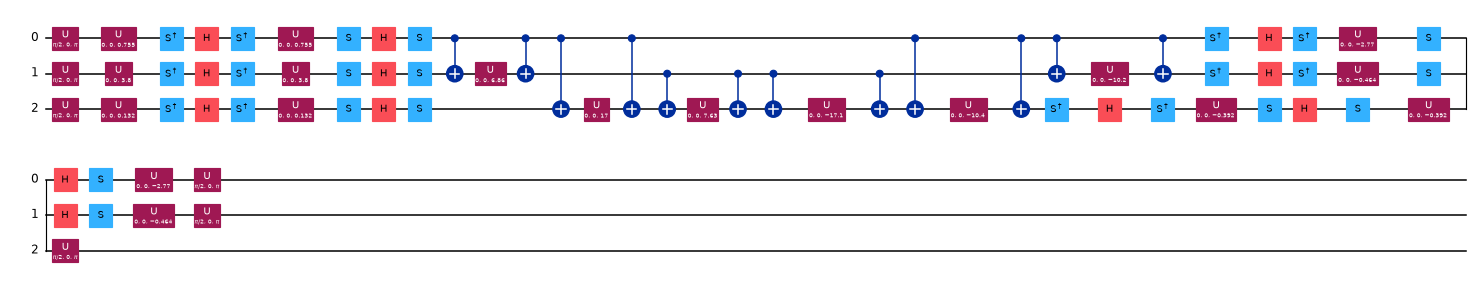

In [12]:
# One kernel entry as a circuit: U(x')^dagger U(x) |000>, probability of |000> == k(x, x'). Checked against the kernel used by the QSVC.
xa, xb = D["A_tr"][0], D["A_tr"][1]
ker_circ = FEATURE_MAP.assign_parameters(xa).compose(FEATURE_MAP.assign_parameters(xb).inverse())
describe("Kernel circuit U(x')^dagger U(x) for two real training flows", ker_circ, "(numbers bound) ")
p000 = Statevector(ker_circ).probabilities_dict().get("000", 0.0)
k_val = kernel_plain.evaluate(np.array([xa]), np.array([xb]))[0, 0]
assert abs(p000 - k_val) < 1e-10, (p000, k_val)
print(f"P(|000>) after the kernel circuit = {p000:.6f} == kernel value {k_val:.6f}  ->  circuit and kernel agree")
display(ker_circ.decompose().draw("mpl", fold=40, scale=0.55))

## 5. Quantum Support Vector Classifier (QSVC), without optimiser

`QSVC` from `qiskit_machine_learning` takes the quantum kernel and trains an SVM on it (here `C = 1`). It computes the training Gram matrix, solves the SVM dual problem classically, and evaluates kernel entries between each test flow and the training flows at prediction time. The same classifier is also fitted by hand as `SVC(kernel="precomputed")` on the Gram matrices to confirm that the two agree.

In [13]:
def run_qsvc(D, kernel, seed, c=SVC_C):
    algorithm_globals.random_seed = seed
    t0 = time.time()
    qsvc = QSVC(quantum_kernel=kernel, C=c)
    qsvc.fit(D["A_tr"], D["y_tr"]); p = qsvc.predict(D["A_te"])
    t = time.time() - t0
    return dict(pred=p, time=t, model=qsvc, **score(D["y_te"], p))

QS = run_qsvc(D, kernel_plain, SEED)
# the same model by hand: precomputed Gram matrices
K_tr = kernel_plain.evaluate(D["A_tr"]); K_te = kernel_plain.evaluate(D["A_te"], D["A_tr"])
hand = SVC(kernel="precomputed", C=SVC_C).fit(K_tr, D["y_tr"])
assert np.array_equal(hand.predict(K_te), QS["pred"]), "QSVC and precomputed SVC disagree"
print("QSVC predictions == SVC(kernel='precomputed') on the same Gram matrices")
print(f"QSVC (untrained kernel): accuracy {QS['acc']:.2f} %, precision {QS['prec']:.4f}, recall {QS['rec']:.4f}, F1 {QS['f1']:.4f}, time {QS['time']:.1f} s")
n_sv = int(QS["model"].n_support_.sum())
print(f"QSVC support vectors: {n_sv} = {n_sv / len(D['y_tr']):.1%} of the training flows | CSVC (4 features): {int(svc4.n_support_.sum())} = {svc4.n_support_.sum() / len(D['y_tr']):.1%}")

QSVC predictions == SVC(kernel='precomputed') on the same Gram matrices
QSVC (untrained kernel): accuracy 88.00 %, precision 0.8462, recall 0.7333, F1 0.7857, time 1.7 s
QSVC support vectors: 265 = 33.1% of the training flows | CSVC (4 features): 249 = 31.1%


## 6. Quantum Random Forest (QRF), without optimiser

The paper's QRF (Section 3.5) is a bagged ensemble of $T$ quantum decision trees whose class probabilities are averaged, $\tilde y(\vec x) = \arg\max_c \frac1T\sum_t Q_t(\vec x; c)$ (eq. 7). It cites Srikumar, Hill and Hollenberg, "A kernel-based quantum random forest for improved classification" (2024), and gives no further detail. This notebook implements the idea in the simplest way that is true to it: **every node of a tree is a quantum-kernel decision**. At a node, several pairs of training exemplars $(a, b)$ with $a$ from class 0 and $b$ from class 1 are drawn at random; a flow $x$ goes to the left child if $k(x, a) \ge k(x, b)$ (it is closer to $a$ in the quantum feature space) and to the right child otherwise; the pair with the largest Gini-impurity decrease is kept (`# CHOICE:`). Each tree is grown on a bootstrap sample of the training flows (the "partition" of the paper), and the leaves store the fraction of attacks. A kernel entry is one run of the kernel circuit of the circuit section, and all entries come from the same Gram matrix as the QSVC, so the QRF costs no extra circuit evaluations once the Gram matrices exist.

The cell also fits the *same* forest with a classical RBF kernel in place of the quantum one, to separate what the quantum kernel contributes from what the tree structure contributes.

In [14]:
class KernelForest:
    """Random forest of kernel-decision trees. Node rule: go left if K(x, a) >= K(x, b) for two exemplars a (class 0) and b (class 1)."""
    def __init__(self, n_trees=QRF_TREES, max_depth=QRF_DEPTH, min_split=QRF_MIN_SPLIT, n_cand=QRF_CANDIDATES, seed=0):
        self.n_trees, self.max_depth, self.min_split, self.n_cand, self.seed = n_trees, max_depth, min_split, n_cand, seed

    @staticmethod
    def _gini(y):
        return 0.0 if len(y) == 0 else 2 * y.mean() * (1 - y.mean())

    def _grow(self, K, y, idx, depth, rng):
        yy = y[idx]; p1 = float(yy.mean())
        if depth >= self.max_depth or len(idx) < self.min_split or p1 in (0.0, 1.0):
            return ("leaf", p1)
        i0, i1 = idx[yy == 0], idx[yy == 1]
        parent, best = self._gini(yy), None
        for _ in range(self.n_cand):
            a, b = int(rng.choice(i0)), int(rng.choice(i1))
            left = K[idx, a] >= K[idx, b]
            if left.all() or (~left).all():
                continue
            gain = parent - (left.sum() * self._gini(yy[left]) + (~left).sum() * self._gini(yy[~left])) / len(idx)
            if best is None or gain > best[0]:
                best = (gain, a, b, left)
        if best is None or best[0] <= 1e-12:
            return ("leaf", p1)
        _, a, b, left = best
        return ("node", a, b, self._grow(K, y, idx[left], depth + 1, rng), self._grow(K, y, idx[~left], depth + 1, rng))

    def fit(self, K_train, y):
        rng = np.random.default_rng(self.seed); n = len(y)
        self.trees_ = [self._grow(K_train, y, rng.integers(0, n, n), 0, rng) for _ in range(self.n_trees)]   # bootstrap partitions
        return self

    def _predict_tree(self, node, Kx, rows, out):
        if node[0] == "leaf":
            out[rows] = node[1]; return
        _, a, b, l, r = node
        go_left = Kx[rows, a] >= Kx[rows, b]
        if go_left.any(): self._predict_tree(l, Kx, rows[go_left], out)
        if (~go_left).any(): self._predict_tree(r, Kx, rows[~go_left], out)

    def predict_proba(self, K_test_train):
        acc = np.zeros(len(K_test_train))
        for tree in self.trees_:
            out = np.zeros(len(K_test_train)); self._predict_tree(tree, K_test_train, np.arange(len(K_test_train)), out); acc += out
        return acc / len(self.trees_)

    def predict(self, K_test_train):
        return (self.predict_proba(K_test_train) >= 0.5).astype(int)

    def n_nodes(self):
        def count(n): return 1 if n[0] == "leaf" else 1 + count(n[3]) + count(n[4])
        return int(np.mean([count(t) for t in self.trees_]))

def run_qrf(D, Ktr, Kte, seed):
    t0 = time.time()
    forest = KernelForest(seed=seed).fit(Ktr, D["y_tr"]); p = forest.predict(Kte)
    return dict(pred=p, time=time.time() - t0, model=forest, **score(D["y_te"], p))

t0 = time.time(); K_tr = kernel_plain.evaluate(D["A_tr"]); K_te = kernel_plain.evaluate(D["A_te"], D["A_tr"]); t_gram = time.time() - t0
QR = run_qrf(D, K_tr, K_te, SEED); QR["time"] += t_gram
print(f"QRF (untrained quantum kernel): accuracy {QR['acc']:.2f} %, precision {QR['prec']:.4f}, recall {QR['rec']:.4f}, F1 {QR['f1']:.4f}, time {QR['time']:.1f} s (incl. {t_gram:.1f} s Gram matrices)")
print(f"  {QRF_TREES} trees, depth <= {QRF_DEPTH}, about {QR['model'].n_nodes()} nodes per tree")

# control: the same forest with a classical RBF kernel on the same 3 angles
gamma = 1.0 / (D["A_tr"].shape[1] * D["A_tr"].var())
QR_rbf = run_qrf(D, rbf_kernel(D["A_tr"], gamma=gamma), rbf_kernel(D["A_te"], D["A_tr"], gamma=gamma), SEED)
print(f"control, same forest with an RBF kernel on the 3 angles: accuracy {QR_rbf['acc']:.2f} %, F1 {QR_rbf['f1']:.4f}")

QRF (untrained quantum kernel): accuracy 90.50 %, precision 0.8596, recall 0.8167, F1 0.8376, time 11.5 s (incl. 2.3 s Gram matrices)
  30 trees, depth <= 8, about 57 nodes per tree


control, same forest with an RBF kernel on the 3 angles: accuracy 88.50 %, F1 0.7850


## 7. "With optimiser": training the quantum kernel with COBYLA

The paper reports a second set of results "with optimiser" and says that COBYLA, L-BFGS-B and SPSA were tried at `maxiter = 100`, with COBYLA best. A support vector classifier built on a fixed kernel has no quantum parameters to optimise, so the paper does not say *what* the optimiser tunes. Its Fig. 9 shows "a parameterised quantum circuit ... applied to the loaded quantum data" with "tunable parameters or weights". Two readings are tested here:

- **(a) a trainable quantum kernel** (this section): a layer of single-qubit rotations $R_Y(\theta_i)$, one per qubit, is placed in front of the feature map, $k_\theta(x, x') = |\langle 0|U_\theta^\dagger(x')\,U_\theta(x)|0\rangle|^2$ with $U_\theta(x) = U_\Phi(x)\prod_i R_{Y_i}(\theta_i)$. Qiskit's `QuantumKernelTrainer` minimises the SVC dual loss on the **training split only** with COBYLA, `maxiter = 100`, starting from $\theta = 0$, which is exactly the untrained kernel of Sections 5-6, so training can only improve the training loss. The QSVC and the QRF are then rebuilt on the trained kernel.
- **(b) a variational classifier** (Section 7b): the feature map followed by a `RealAmplitudes` ansatz trained with COBYLA.

trainable kernel at theta = 0 equals the untrained kernel


COBYLA maxiter=100: 96 loss evaluations in 108 s | SVC dual loss 241.84 -> 240.21 | theta* = [-0.146  0.476 -0.481]


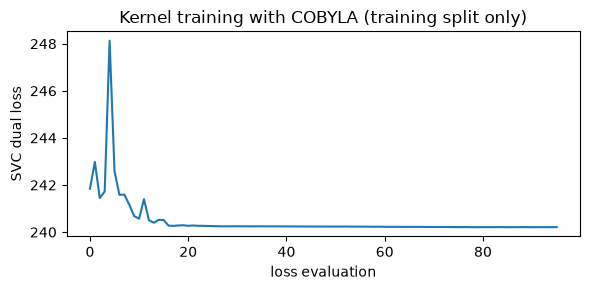

In [15]:
THETA = ParameterVector("θ", N_QUBITS)
def trainable_circuit():
    qc = QuantumCircuit(N_QUBITS)
    for i in range(N_QUBITS):
        qc.ry(THETA[i], i)                       # CHOICE: where the trainable angles sit (before the feature map)
    return qc.compose(FEATURE_MAP)

class RecordingSVCLoss(SVCLoss):
    def __init__(self, **kw):
        super().__init__(**kw); self.history = []
    def evaluate(self, parameter_values, quantum_kernel, data, labels):
        v = super().evaluate(parameter_values, quantum_kernel, data, labels); self.history.append(v); return v

def train_kernel(D, optimizer, seed, n_train=None, init=None):
    # returns (trained kernel, result, loss history, seconds); training uses the training split only
    algorithm_globals.random_seed = seed
    X, y = D["A_tr"], D["y_tr"]
    if n_train is not None and n_train < len(y):
        idx = np.random.default_rng(seed).choice(len(y), n_train, replace=False); X, y = X[idx], y[idx]
    kern = FastTrainableKernel(feature_map=trainable_circuit(), training_parameters=THETA)
    loss = RecordingSVCLoss(C=SVC_C)
    trainer = QuantumKernelTrainer(quantum_kernel=kern, loss=loss, optimizer=optimizer, initial_point=np.zeros(N_QUBITS) if init is None else init)
    t0 = time.time(); res = trainer.fit(X, y)
    return res.quantum_kernel, res, loss.history, time.time() - t0

# sanity: theta = 0 reproduces the untrained kernel
k0 = FastTrainableKernel(feature_map=trainable_circuit(), training_parameters=THETA); k0.assign_training_parameters(np.zeros(N_QUBITS))
assert np.allclose(k0.evaluate(D["A_tr"][:50]), kernel_plain.evaluate(D["A_tr"][:50]), atol=1e-10)
print("trainable kernel at theta = 0 equals the untrained kernel")

kernel_opt, res_opt, hist_opt, t_train = train_kernel(D, COBYLA(maxiter=KERNEL_MAXITER), SEED, n_train=KERNEL_TRAIN_N)
theta_opt = np.asarray(res_opt.optimal_point)
print(f"COBYLA maxiter={KERNEL_MAXITER}: {len(hist_opt)} loss evaluations in {t_train:.0f} s | SVC dual loss {hist_opt[0]:.2f} -> {res_opt.optimal_value:.2f} | theta* = {np.round(theta_opt, 3)}")
fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(hist_opt); ax.set_xlabel("loss evaluation"); ax.set_ylabel("SVC dual loss"); ax.set_title("Kernel training with COBYLA (training split only)")
plt.tight_layout(); plt.show()

In [16]:
QS_opt = run_qsvc(D, kernel_opt, SEED)
t0 = time.time(); Ktr_o = kernel_opt.evaluate(D["A_tr"]); Kte_o = kernel_opt.evaluate(D["A_te"], D["A_tr"]); t_gram_o = time.time() - t0
QR_opt = run_qrf(D, Ktr_o, Kte_o, SEED); QR_opt["time"] += t_gram_o
for name, r in {"QSVC (trained kernel)": QS_opt, "QRF (trained kernel)": QR_opt}.items():
    print(f"{name:24s}: accuracy {r['acc']:.2f} %, precision {r['prec']:.4f}, recall {r['rec']:.4f}, F1 {r['f1']:.4f}, time {r['time']:.1f} s")
print(f"untrained for comparison : QSVC {QS['acc']:.2f} %, QRF {QR['acc']:.2f} %")

QSVC (trained kernel)   : accuracy 88.50 %, precision 0.8627, recall 0.7333, F1 0.7928, time 2.8 s
QRF (trained kernel)    : accuracy 90.00 %, precision 0.8448, recall 0.8167, F1 0.8305, time 12.1 s
untrained for comparison : QSVC 88.00 %, QRF 90.50 %


### 7a. Which optimiser? L-BFGS-B, SPSA and COBYLA

The paper tried "L_BFGS_B, SPSA and COBYLA" with `maxiter = 100` and found COBYLA best, without saying on which data or by which metric. Here each optimiser trains the kernel on a small training subset and is scored by the QSVC accuracy on a **validation set drawn from the remaining training flows** (never the test flows).

In [17]:
algorithm_globals.random_seed = SEED
tr_idx = np.random.default_rng(SEED).permutation(len(D["y_tr"]))
sub = tr_idx[:OPT_STUDY_TRAIN]; val = tr_idx[OPT_STUDY_TRAIN:OPT_STUDY_TRAIN + OPT_STUDY_VAL]
Dsub = dict(A_tr=D["A_tr"][sub], y_tr=D["y_tr"][sub])
Xv, yv = D["A_tr"][val], D["y_tr"][val]
rows = []
base = QSVC(quantum_kernel=kernel_plain, C=SVC_C).fit(Dsub["A_tr"], Dsub["y_tr"])
rows.append(dict(optimiser="none (theta = 0)", val_acc=100 * accuracy_score(yv, base.predict(Xv)), evals=0, seconds=0.0))
for name, opt in {"L_BFGS_B": L_BFGS_B(maxiter=OPT_STUDY_MAXITER), "SPSA": SPSA(maxiter=OPT_STUDY_MAXITER), "COBYLA": COBYLA(maxiter=OPT_STUDY_MAXITER)}.items():
    init = None if name != "SPSA" else np.zeros(N_QUBITS)
    kern, res, hist, secs = train_kernel(Dsub, opt, SEED, init=init)
    m = QSVC(quantum_kernel=kern, C=SVC_C).fit(Dsub["A_tr"], Dsub["y_tr"])
    rows.append(dict(optimiser=name, val_acc=100 * accuracy_score(yv, m.predict(Xv)), evals=len(hist), seconds=secs, final_loss=res.optimal_value))
opt_df = pd.DataFrame(rows).set_index("optimiser").round(2)
print(f"kernel trained on {len(sub)} flows, scored on {len(val)} held-out TRAINING flows, maxiter = {OPT_STUDY_MAXITER}")
display(opt_df)
best_opt = opt_df.drop(index="none (theta = 0)")["val_acc"].idxmax()
print("best optimiser on validation accuracy:", best_opt, "(paper: COBYLA)")

kernel trained on 150 flows, scored on 150 held-out TRAINING flows, maxiter = 100


,val_acc,evals,seconds,final_loss
optimiser,,,,
none (theta = 0),85.33,0,0.00,NaN
L_BFGS_B,85.33,244,123.24,54.25
SPSA,85.33,251,114.24,51.66
COBYLA,84.67,55,26.35,50.81


best optimiser on validation accuracy: L_BFGS_B (paper: COBYLA)


### 7b. The other reading: a variational quantum classifier

If the paper's "parameterised quantum circuit" is an ansatz appended to the feature map (the usual Qiskit layout, and Fig. 9's caption "used in optimisation process"), the model is a `VQC`: feature map, `RealAmplitudes` ansatz (3 qubits, 2 repetitions, 9 weights), measurement of all qubits, class read from the bit-string parity, COBYLA with `maxiter = 100`, shot-based Aer simulation. Its cost per optimiser step grows with the number of training flows, so a subset of the training split is used (`VQC_N_TRAIN`); it is evaluated on the same test flows.

VQC (feature map + RealAmplitudes + COBYLA 100), trained on 200 flows: accuracy 81.50 %, precision 0.7949, recall 0.5167, F1 0.6263, time 1187 s


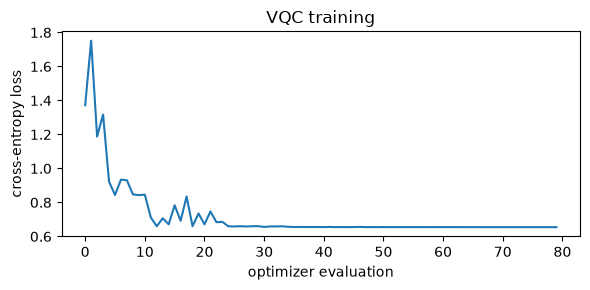

In [18]:
vqc = None; VQ = None
if RUN_VQC:
    algorithm_globals.random_seed = SEED
    vqc_hist = []
    fm_v = pauli_feature_map(N_QUBITS, reps=FM_REPS, paulis=PAULIS)
    ansatz = real_amplitudes(N_QUBITS, reps=2)                                  # CHOICE: ansatz and repetitions (the paper shows a circuit but no gates)
    vqc = VQC(feature_map=fm_v, ansatz=ansatz, optimizer=COBYLA(maxiter=VQC_MAXITER),
              sampler=AerSampler(default_shots=SHOTS, seed=SEED), callback=lambda w, l: vqc_hist.append(l))
    vi = np.random.default_rng(SEED).permutation(len(D["y_tr"]))[:VQC_N_TRAIN]
    t0 = time.time(); vqc.fit(D["A_tr"][vi], D["y_tr"][vi]); p = vqc.predict(D["A_te"]); t_v = time.time() - t0
    VQ = dict(pred=p, time=t_v, model=vqc, **score(D["y_te"], p))
    print(f"VQC (feature map + RealAmplitudes + COBYLA {VQC_MAXITER}), trained on {VQC_N_TRAIN} flows: accuracy {VQ['acc']:.2f} %, precision {VQ['prec']:.4f}, recall {VQ['rec']:.4f}, F1 {VQ['f1']:.4f}, time {t_v:.0f} s")
    fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(vqc_hist); ax.set_xlabel("optimizer evaluation"); ax.set_ylabel("cross-entropy loss"); ax.set_title("VQC training"); plt.tight_layout(); plt.show()

### Circuit drawings of the trained models

The trainable kernel circuit with the learned angles inserted, and the circuit of the variational classifier that was trained above (taken from the trained `VQC` object, with the measurement that the sampler appends).

Trainable kernel circuit R_Y(theta) + PauliFeatureMap (before training: theta symbolic): 3 qubits | depth 19 (decomposed to basic gates) | 6 parameters (3 trainable theta + 3 data inputs) | gates {'u': 33, 'cx': 6}
... with the COBYLA-trained angles inserted: 3 qubits | depth 19 (decomposed to basic gates) | 3 parameters (data inputs only) | gates {'u': 33, 'cx': 6}


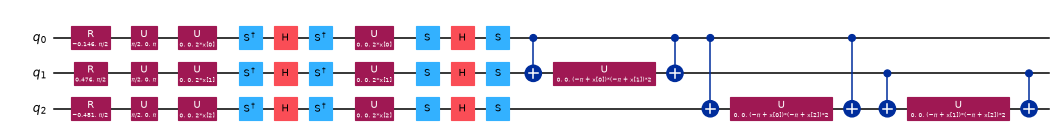

trained-kernel circuit: P(|000>) equals the trained kernel value for a real pair of flows


In [19]:
tc = trainable_circuit()
tc_bound = tc.assign_parameters({THETA[i]: float(theta_opt[i]) for i in range(N_QUBITS)})          # trained angles, data x still symbolic
describe("Trainable kernel circuit R_Y(theta) + PauliFeatureMap (before training: theta symbolic)", tc, f"({N_QUBITS} trainable theta + {FEATURE_MAP.num_parameters} data inputs) ")
describe("... with the COBYLA-trained angles inserted", tc_bound, "(data inputs only) ")
display(tc_bound.decompose().draw("mpl", fold=40, scale=0.55))
# the circuit actually run by the trained kernel for one flow, checked against its kernel value
xa, xb = D["A_tr"][0], D["A_tr"][1]
kc = tc_bound.assign_parameters(xa).compose(tc_bound.assign_parameters(xb).inverse())
assert abs(Statevector(kc).probabilities_dict().get("000", 0.0) - kernel_opt.evaluate(np.array([xa]), np.array([xb]))[0, 0]) < 1e-10
print("trained-kernel circuit: P(|000>) equals the trained kernel value for a real pair of flows")

VQC circuit (PauliFeatureMap + RealAmplitudes + measurement): 3 qubits | depth 26 (decomposed to basic gates) | 12 parameters (9 trainable weights + 3 data inputs) | gates {'u': 39, 'cx': 10, 'measure': 3}
trainable parameters (ansatz weights): 9 | trained weights: [1.576 0.992 0.383 2.745 1.451 0.658 0.51  0.828 1.039]


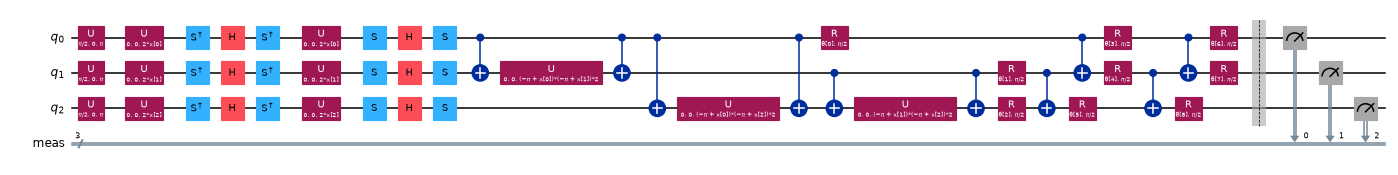

In [20]:
if vqc is not None:
    vqc_circ = vqc.neural_network.circuit.measure_all(inplace=False)
    describe("VQC circuit (PauliFeatureMap + RealAmplitudes + measurement)", vqc_circ, f"({vqc.ansatz.num_parameters} trainable weights + {vqc.feature_map.num_parameters} data inputs) ")
    print("trainable parameters (ansatz weights):", vqc.ansatz.num_parameters, "| trained weights:", np.round(vqc.weights, 3))
    display(vqc_circ.decompose().draw("mpl", fold=40, scale=0.55))
else:
    print("RUN_VQC = False: no variational circuit to draw")

**Assumptions where the paper omits circuit details (all marked `# CHOICE:` in the code).** The paper gives the feature map as `PauliFeatureMap` with dimension three, one repetition and Paulis "z, y, z" but shows no gate list, so this notebook uses `["Z", "Y", "ZZ"]` with Qiskit's default full entanglement (all three qubit pairs). It does not say what the optimiser trains: the trainable kernel (rotations before the feature map) and the `RealAmplitudes` variational classifier are two readings, and neither is confirmed by the paper. The QRF has no circuit in the paper beyond a tree diagram (Fig. 10); here its nodes read kernel entries computed with the circuit above. No noise model, transpilation to a device or real hardware is used, which matches the paper's noiseless simulation.

## 8. Results: Tables 1 and 2 of the paper

The main run (seed 42) in the layout of the paper's tables: accuracy without and with optimiser, then precision, recall, F1 and run time. Classical models appear on the paper's 4 features (the setting used for the verdicts), on the 3 angles the quantum models read, and on all features. "With optimiser" for the quantum models is the trained-kernel reading of Section 7; the variational classifier is listed separately.

,accuracy (%),precision,recall,F1,time (s),paper accuracy (%),paper F1,acc. gap
CSVC,88.5,0.8627,0.7333,0.7928,0.0256,96.44,0.9550,-7.94
CRF,91.5,0.8772,0.8333,0.8547,2.6053,96.65,0.9640,-5.15
QSVC,88.0,0.8462,0.7333,0.7857,1.6956,95.37,NaN,-7.37
QRF,90.5,0.8596,0.8167,0.8376,11.4711,98.00,NaN,-7.50
QSVC+opt,88.5,0.8627,0.7333,0.7928,2.8094,99.20,0.9931,-10.70
QRF+opt,90.0,0.8448,0.8167,0.8305,12.1429,99.78,0.9867,-9.78


additional models (not in the paper's tables):


,accuracy (%),precision,recall,F1,time (s)
CSVC (3 PCA angles),88.5,0.8627,0.7333,0.7928,0.0951
CRF (3 PCA angles),91.0,0.8621,0.8333,0.8475,1.7270
CSVC (all features),90.5,0.9020,0.7667,0.8288,0.1198
CRF (all features),95.0,0.9808,0.8500,0.9107,1.8908
"QRF control, RBF kernel",88.5,0.8936,0.7000,0.7850,8.4501
"VQC (COBYLA, reading b)",81.5,0.7949,0.5167,0.6263,1186.9632


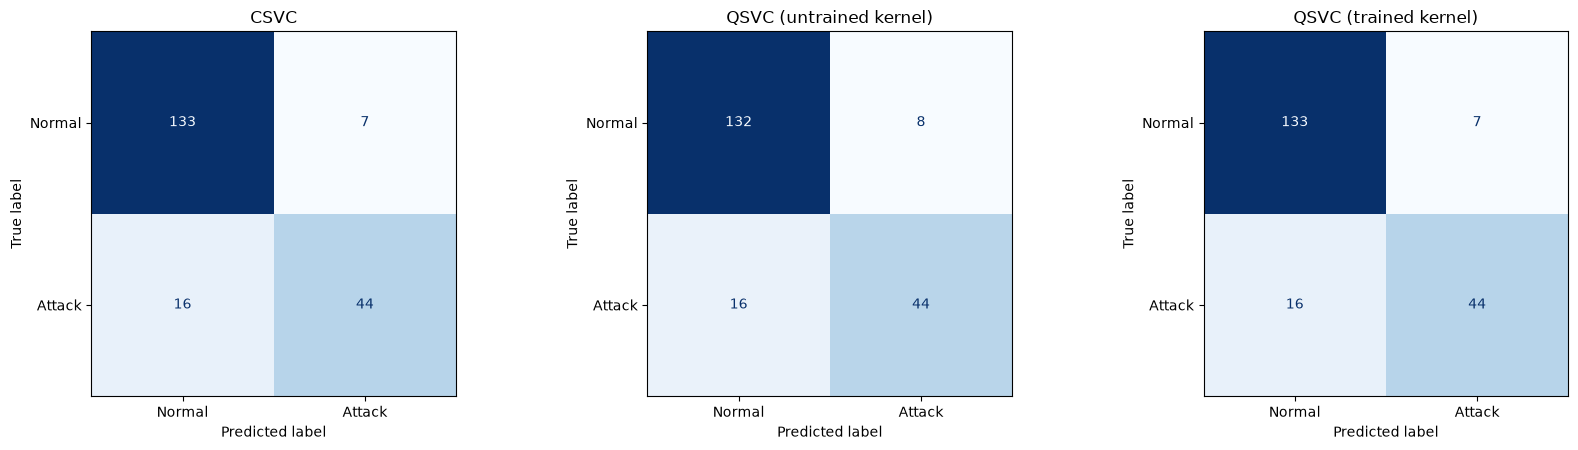

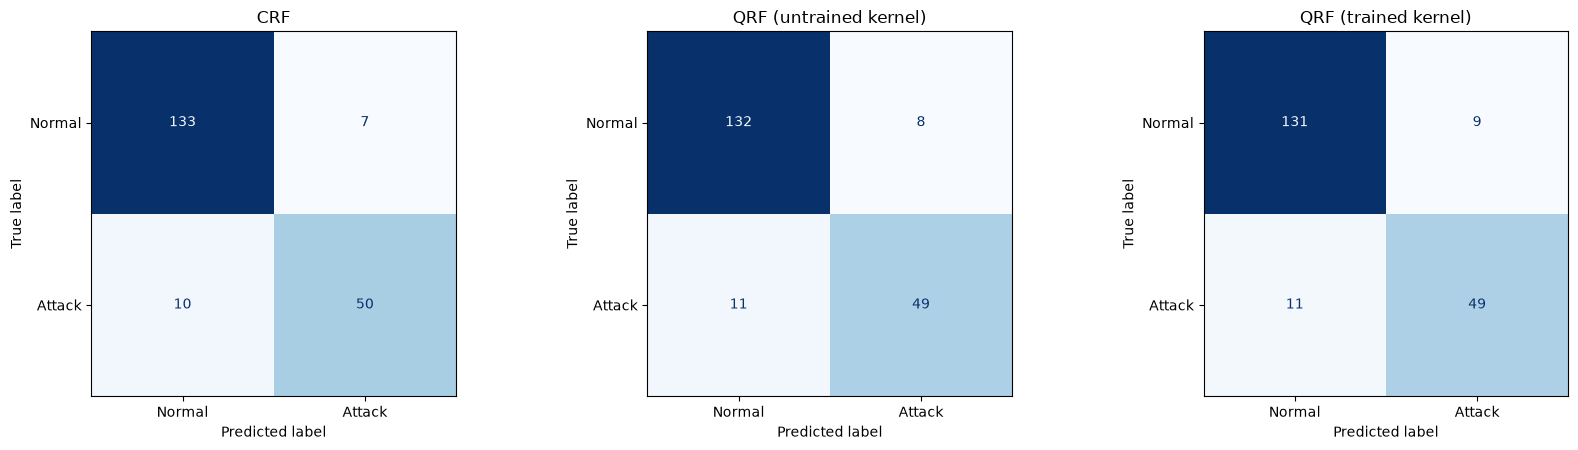

In [21]:
R = {"CSVC": CL["CSVC (4 features)"], "CRF": CL["CRF (4 features)"], "QSVC": QS, "QRF": QR, "QSVC+opt": QS_opt, "QRF+opt": QR_opt}
EXTRA = {"CSVC (3 PCA angles)": CL["CSVC (3 PCA angles)"], "CRF (3 PCA angles)": CL["CRF (3 PCA angles)"], "CSVC (all features)": CL["CSVC (all features)"],
         "CRF (all features)": CL["CRF (all features)"], "QRF control, RBF kernel": QR_rbf}
if VQ is not None: EXTRA["VQC (COBYLA, reading b)"] = VQ

PAPER_T1 = {"CSVC": 96.44, "CRF": 96.65, "QSVC": 95.37, "QRF": 98.0, "QSVC+opt": 99.2, "QRF+opt": 99.78}
PAPER_T2 = {"CSVC": (0.9734, 0.9611, 0.955), "CRF": (0.9622, 0.9413, 0.964), "QSVC+opt": (0.9932, 0.9845, 0.9931), "QRF+opt": (0.9873, 0.9812, 0.9867)}

main_tab = pd.DataFrame({k: {"accuracy (%)": v["acc"], "precision": v["prec"], "recall": v["rec"], "F1": v["f1"], "time (s)": v["time"],
                             "paper accuracy (%)": PAPER_T1[k], "paper F1": PAPER_T2.get(k, (None, None, None))[2]} for k, v in R.items()}).T
main_tab["acc. gap"] = main_tab["accuracy (%)"] - main_tab["paper accuracy (%)"]
display(main_tab.round(4))
extra_tab = pd.DataFrame({k: {"accuracy (%)": v["acc"], "precision": v["prec"], "recall": v["rec"], "F1": v["f1"], "time (s)": v["time"]} for k, v in EXTRA.items()}).T
print("additional models (not in the paper's tables):")
display(extra_tab.round(4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a_, (name, r) in zip(ax, [("CSVC", R["CSVC"]), ("QSVC (untrained kernel)", R["QSVC"]), ("QSVC (trained kernel)", R["QSVC+opt"])]):
    ConfusionMatrixDisplay(confusion_matrix(D["y_te"], r["pred"], labels=[0, 1]), display_labels=["Normal", "Attack"]).plot(ax=a_, cmap="Blues", colorbar=False); a_.set_title(name)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a_, (name, r) in zip(ax, [("CRF", R["CRF"]), ("QRF (untrained kernel)", R["QRF"]), ("QRF (trained kernel)", R["QRF+opt"])]):
    ConfusionMatrixDisplay(confusion_matrix(D["y_te"], r["pred"], labels=[0, 1]), display_labels=["Normal", "Attack"]).plot(ax=a_, cmap="Blues", colorbar=False); a_.set_title(name)
plt.tight_layout(); plt.show()

## 9. Robustness: other random draws of the 1000 flows

One draw of 1000 flows and one 200-flow test set make every accuracy uncertain by about $\pm 2$ points, which is the size of the gaps the paper discusses. The whole pipeline (sampling, feature selection, PCA, all models, kernel training) is repeated for each seed in `SEEDS`; the first seed is the main run above.

seed 43: 797 s | selected ['sttl', 'ct_dst_sport_ltm', 'rate', 'ct_src_dport_ltm'] | CSVC 86.5, CRF 90.5, QSVC 84.5, QRF 88.0, QSVC+opt 84.5, QRF+opt 87.5


seed 44: 471 s | selected ['sttl', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_state_ttl'] | CSVC 83.5, CRF 90.0, QSVC 89.5, QRF 90.5, QSVC+opt 89.5, QRF+opt 89.5


3 random draws: [42, 43, 44]


,accuracy mean (%),accuracy std,F1 mean,F1 std,paper accuracy (%)
CSVC,86.167,2.055,0.735,0.046,96.44
CRF,90.667,0.624,0.845,0.009,96.65
QSVC,87.333,2.095,0.780,0.047,95.37
QRF,89.667,1.179,0.824,0.019,98.00
QSVC+opt,87.500,2.160,0.783,0.047,99.20
QRF+opt,89.000,1.080,0.815,0.018,99.78
CSVC (3 PCA angles),86.500,1.414,0.762,0.026,NaN
CRF (3 PCA angles),89.000,1.472,0.820,0.019,NaN


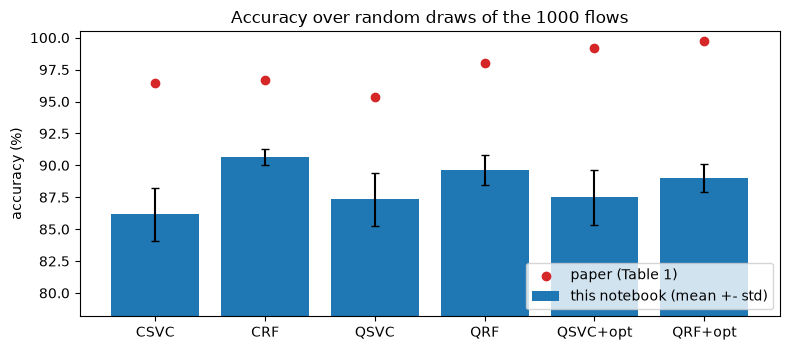

In [22]:
def run_all(Dd, seed):
    cl = run_classical(Dd, seed)
    kp = FastFidelityKernel(feature_map=FEATURE_MAP)
    qs = run_qsvc(Dd, kp, seed)
    t0 = time.time(); Ktr_ = kp.evaluate(Dd["A_tr"]); Kte_ = kp.evaluate(Dd["A_te"], Dd["A_tr"]); tg = time.time() - t0
    qr = run_qrf(Dd, Ktr_, Kte_, seed); qr["time"] += tg
    ko, ro, ho, tt = train_kernel(Dd, COBYLA(maxiter=KERNEL_MAXITER), seed, n_train=KERNEL_TRAIN_N)
    qso = run_qsvc(Dd, ko, seed)
    t0 = time.time(); Ktr_o = ko.evaluate(Dd["A_tr"]); Kte_o = ko.evaluate(Dd["A_te"], Dd["A_tr"]); tgo = time.time() - t0
    qro = run_qrf(Dd, Ktr_o, Kte_o, seed); qro["time"] += tgo
    return {"CSVC": cl["CSVC (4 features)"], "CRF": cl["CRF (4 features)"], "CSVC (3 PCA angles)": cl["CSVC (3 PCA angles)"], "CRF (3 PCA angles)": cl["CRF (3 PCA angles)"],
            "QSVC": qs, "QRF": qr, "QSVC+opt": qso, "QRF+opt": qro}

ALL = {SEEDS[0]: {**R, "CSVC (3 PCA angles)": CL["CSVC (3 PCA angles)"], "CRF (3 PCA angles)": CL["CRF (3 PCA angles)"]}}
for sd in SEEDS[1:]:
    t0 = time.time(); Dd = prepare(sd); ALL[sd] = run_all(Dd, sd)
    print(f"seed {sd}: {time.time() - t0:.0f} s | selected {Dd['sel']} | " + ", ".join(f"{k} {v['acc']:.1f}" for k, v in ALL[sd].items() if k in PAPER_T1))
models = list(ALL[SEEDS[0]].keys())
acc_df = pd.DataFrame({sd: {m: ALL[sd][m]["acc"] for m in models} for sd in SEEDS}).T
f1_df = pd.DataFrame({sd: {m: ALL[sd][m]["f1"] for m in models} for sd in SEEDS}).T
summary = pd.DataFrame({"accuracy mean (%)": acc_df.mean(), "accuracy std": acc_df.std(ddof=0), "F1 mean": f1_df.mean(), "F1 std": f1_df.std(ddof=0)})
summary["paper accuracy (%)"] = pd.Series(PAPER_T1)
print(f"{len(SEEDS)} random draws: {SEEDS}")
display(summary.round(3))
ok = [m for m in models if m in PAPER_T1]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(ok)), summary.loc[ok, "accuracy mean (%)"], yerr=summary.loc[ok, "accuracy std"], capsize=3, color="tab:blue", label="this notebook (mean +- std)")
ax.scatter(range(len(ok)), summary.loc[ok, "paper accuracy (%)"], color="tab:red", zorder=3, label="paper (Table 1)")
ax.set_xticks(range(len(ok))); ax.set_xticklabels(ok); ax.set_ylabel("accuracy (%)"); ax.set_ylim(max(0, summary.loc[ok, "accuracy mean (%)"].min() - 8), 100.5); ax.legend(loc="lower right")
ax.set_title("Accuracy over random draws of the 1000 flows"); plt.tight_layout(); plt.show()

## 10. Side by side with the paper: a verdict per claim

Rule: a number is **reproduced** if it lies within 2 accuracy points (0.02 for precision, recall and F1) of the paper's value, **exceeded** or **not reached** otherwise, with the gap; **cannot be checked** when the paper's value is not comparable. The primary comparison uses the mean over the random draws; the main (seed 42) run is shown in Section 8.

In [23]:
def verdict(ours, paper, tol):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})")

ledger = []
for m, p in PAPER_T1.items():
    ledger.append(("C1" if "opt" not in m else "C2", f"Table 1 accuracy (%), {m}", p, round(summary.loc[m, "accuracy mean (%)"], 2), verdict(summary.loc[m, "accuracy mean (%)"], p, 2.0)))
for m, (p, r, f) in PAPER_T2.items():
    for nm, pv, key in (("precision", p, "prec"), ("recall", r, "rec"), ("F1", f, "f1")):
        ours = float(np.mean([ALL[sd][m][key] for sd in SEEDS]))
        ledger.append(("C3", f"Table 2 {nm}, {m}", pv, round(ours, 4), verdict(ours, pv, 0.02)))
acc = summary["accuracy mean (%)"]
q_gt_c = bool(acc["QSVC+opt"] > acc["CSVC"] and acc["QRF+opt"] > acc["CRF"])
ledger.append(("C4", "optimised quantum models beat their classical counterparts", "yes", "yes" if q_gt_c else "no", "reproduced" if q_gt_c else "not reached here"))
best_cl = max(acc["CSVC"], acc["CRF"])
ledger.append(("C4", "classical models plateau around 96 %", "~96", round(best_cl, 2), verdict(best_cl, 96.0, 2.0)))
imp = bool(acc["QSVC+opt"] > acc["QSVC"] and acc["QRF+opt"] > acc["QRF"])
ledger.append(("C5", "optimiser raises QSVC and QRF accuracy", "+3.8 / +1.8 points", f"{acc['QSVC+opt'] - acc['QSVC']:+.2f} / {acc['QRF+opt'] - acc['QRF']:+.2f}", "reproduced" if imp else "not reached here"))
ledger.append(("C6", "COBYLA best of L-BFGS-B, SPSA, COBYLA", "COBYLA", best_opt, "reproduced" if best_opt == "COBYLA" else "not reached here"))
sv_frac = float(np.mean([ALL[sd]["CSVC"]["model"].n_support_.sum() / (N_SAMPLES * (1 - TEST_SIZE)) for sd in SEEDS]))
ledger.append(("C7", "CSVC support vectors, fraction of the training data", "13 %", f"{sv_frac:.1%}", "reproduced" if abs(100 * sv_frac - 13.0) <= 3.0 else f"not reached ({100 * sv_frac:.1f} % vs 13 %)"))
qsv = QS["model"].n_support_.sum() / len(D["y_tr"]); csv_ = svc4.n_support_.sum() / len(D["y_tr"])
ledger.append(("C7", "QSVC needs fewer support vectors than CSVC", "yes", f"QSVC {qsv:.1%} vs CSVC {csv_:.1%}", "reproduced" if qsv < csv_ else "not reached here"))
faster = R["CSVC"]["time"] < R["QSVC"]["time"] and R["CRF"]["time"] < R["QRF"]["time"]          # each classical model against its quantum counterpart
ledger.append(("C8", "each classical model faster than its simulated quantum counterpart", "4.26 s, 17.5 s vs '200 m', '128 m'", f"{R['CSVC']['time']:.1f} s, {R['CRF']['time']:.1f} s vs {R['QSVC']['time']:.1f} s, {R['QRF']['time']:.1f} s",
               "reproduced in direction (absolute times cannot be checked: the paper's unit 'm' is unclear)" if faster else "not reached here"))
ledger_df = pd.DataFrame(ledger, columns=["claim", "what", "paper", "notebook", "verdict"])
display(ledger_df)
print(ledger_df["verdict"].str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].value_counts().to_dict())

,claim,what,paper,notebook,verdict
0,C1,"Table 1 accuracy (%), CSVC",96.44,86.17,not reached (-10.273)
1,C1,"Table 1 accuracy (%), CRF",96.65,90.67,not reached (-5.983)
2,C1,"Table 1 accuracy (%), QSVC",95.37,87.33,not reached (-8.037)
3,C1,"Table 1 accuracy (%), QRF",98.0,89.67,not reached (-8.333)
4,C2,"Table 1 accuracy (%), QSVC+opt",99.2,87.5,not reached (-11.700)
5,C2,"Table 1 accuracy (%), QRF+opt",99.78,89.0,not reached (-10.780)
6,C3,"Table 2 precision, CSVC",0.9734,0.8597,not reached (-0.114)
7,C3,"Table 2 recall, CSVC",0.9611,0.6444,not reached (-0.317)
8,C3,"Table 2 F1, CSVC",0.955,0.735,not reached (-0.220)
9,C3,"Table 2 precision, CRF",0.9622,0.842,not reached (-0.120)


{'not reached': 24, 'reproduced': 1}


### Internal consistency of the paper's tables

Before trusting the comparison it is worth checking that the paper's own numbers agree with one another (F1 is the harmonic mean of precision and recall, and Table 3 repeats Table 2).

In [24]:
rows = []
for m, (p, r, f) in PAPER_T2.items():
    rows.append(dict(model=m, precision=p, recall=r, **{"F1 reported": f}, **{"F1 from P and R": round(2 * p * r / (p + r), 4)}, **{"difference": round(f - 2 * p * r / (p + r), 4)}))
display(pd.DataFrame(rows).set_index("model"))
print("Table 3 lists CSVC F1 = 95.5, CRF 96.4, QSVC 99.31, QRF 98.67 (%), the same as Table 2; Table 3 prints QSVC precision as 99.32, Table 2 as 0.9932.")
print("Table 1/2 list CRF as the most accurate classical model (96.65 %) but with a lower recall (0.9413) than CSVC (0.9611).")

,precision,recall,F1 reported,F1 from P and R,difference
model,,,,,
CSVC,0.9734,0.9611,0.9550,0.9672,-0.0122
CRF,0.9622,0.9413,0.9640,0.9516,0.0124
QSVC+opt,0.9932,0.9845,0.9931,0.9888,0.0043
QRF+opt,0.9873,0.9812,0.9867,0.9842,0.0025


Table 3 lists CSVC F1 = 95.5, CRF 96.4, QSVC 99.31, QRF 98.67 (%), the same as Table 2; Table 3 prints QSVC precision as 99.32, Table 2 as 0.9932.
Table 1/2 list CRF as the most accurate classical model (96.65 %) but with a lower recall (0.9413) than CSVC (0.9611).


## 11. Reading the paper critically

The next cell prints the numbers that the discussion below rests on; the discussion quotes the full (`FAST_MODE = False`) run, in which the main run is seed 42 and the other two draws are seeds 43 and 44.

In [25]:
# numbers for the discussion
print("seeds:", SEEDS, "| FAST_MODE =", FAST_MODE)
print("classical on 4 features / 3 PCA angles / all features (mean accuracy over seeds):",
      {m: round(float(np.mean([ALL[sd][m]["acc"] for sd in SEEDS])), 2) for m in ["CSVC", "CRF", "CSVC (3 PCA angles)", "CRF (3 PCA angles)"]})
print("test-set size", len(D["y_te"]), "-> one test flow = %.2f accuracy points; a binomial 95 %% interval at 97 %% accuracy is about +-%.1f points" % (100 / len(D["y_te"]), 196 * math.sqrt(.97 * .03 / len(D["y_te"]))))
print("majority-class accuracy of the 70/30 sample:", round(100 * max(np.mean(D["y_te"]), 1 - np.mean(D["y_te"])), 1))
# how much can the 4 selected features say? flows with identical feature values must receive identical predictions
g = D["tr"].groupby(D["sel"])["label"].agg(["size", "mean"])
lookup_acc = 100 * (g["size"] * np.maximum(g["mean"], 1 - g["mean"])).sum() / len(D["tr"])
print(f"the 4 selected features take {len(g)} distinct value combinations in the {len(D['tr'])} training flows; the best possible classifier on them "
      f"(majority label of each combination) scores {lookup_acc:.1f} % on the training split itself")
display(g.sort_values("size", ascending=False).head(6).rename(columns={"mean": "share of attacks"}))
# classical ceiling (not in the paper): the same test flows, but a random forest trained on many more flows from the pool that is disjoint from the 1000-flow sample
pool = full[~full["_rid"].isin(D["s"]["_rid"])]
n_b0 = int(CEILING_N * NORMAL_FRACTION)
big = pd.concat([pool[pool.label == 0].sample(n_b0, random_state=SEED), pool[pool.label == 1].sample(CEILING_N - n_b0, random_state=SEED)])
mm_b = MinMaxScaler().fit(big[D["sel"]])
rf_b4 = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2).fit(mm_b.transform(big[D["sel"]]), big["label"])
acc_b4 = 100 * accuracy_score(D["y_te"], rf_b4.predict(mm_b.transform(D["te"][D["sel"]])))
sc_b = StandardScaler().fit(log1p_clip(big[NUM_COLS].to_numpy(float)))
rf_ba = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2).fit(sc_b.transform(log1p_clip(big[NUM_COLS].to_numpy(float))), big["label"])
acc_ba = 100 * accuracy_score(D["y_te"], rf_ba.predict(sc_b.transform(log1p_clip(D["te"][NUM_COLS].to_numpy(float)))))
print(f"classical ceiling on the same {len(D['y_te'])} test flows, random forest trained on {len(big):,} flows (70/30 mix): 4 selected features {acc_b4:.2f} %, all {len(NUM_COLS)} numeric features {acc_ba:.2f} %  (paper's CRF: 96.65 % on 4 features and 800 training flows)")
print(f"total notebook time so far: {(time.time() - NOTEBOOK_T0) / 60:.1f} min")

seeds: [42, 43, 44] | FAST_MODE = False
classical on 4 features / 3 PCA angles / all features (mean accuracy over seeds): {'CSVC': 86.17, 'CRF': 90.67, 'CSVC (3 PCA angles)': 86.5, 'CRF (3 PCA angles)': 89.0}
test-set size 200 -> one test flow = 0.50 accuracy points; a binomial 95 % interval at 97 % accuracy is about +-2.4 points
majority-class accuracy of the 70/30 sample: 70.0


the 4 selected features take 90 distinct value combinations in the 800 training flows; the best possible classifier on them (majority label of each combination) scores 89.2 % on the training split itself


size  share of attacks
sttl ct_dst_sport_ltm ct_src_dport_ltm swin                        
31   1                1                255    198          0.000000
254  1                1                255    132          0.287879
31   1                1                0       65          0.000000
62   1                1                255     48          0.583333
254  1                1                0       46          0.652174
     16               16               0       21          1.000000

classical ceiling on the same 200 test flows, random forest trained on 20,000 flows (70/30 mix): 4 selected features 91.50 %, all 37 numeric features 97.50 %  (paper's CRF: 96.65 % on 4 features and 800 training flows)
total notebook time so far: 55.5 min


**What the full run shows (3 random draws of 1000 flows, 200 test flows each).**

1. **The paper's accuracies are not reached.** On the paper's 4 features the classical models score 86.2 % (CSVC) and 90.7 % (CRF) against 96.44 % and 96.65 % in Table 1; the quantum models score 87.3 % (QSVC) and 89.7 % (QRF) without optimiser against 95.37 % and 98 %, and 87.5 % and 89.0 % with the trained kernel against 99.2 % and 99.78 %. Every precision, recall and F1 of Table 2 is missed by 0.09 to 0.32. These gaps are far larger than the sampling noise (one test flow is 0.5 accuracy points; a 95 % interval at 97 % accuracy is about +-2.4 points, and the standard deviation over the three draws is 0.6 to 2.2 points).
2. **The paper's classical numbers are already above what this data supports.** A random forest trained on 20,000 flows (25 times more than the paper's 800) reaches 91.5 % on the same test flows when it sees only the 4 selected features, and 97.5 % with all 37 numeric features. A correlation filter that keeps only 4 features cannot give the 96-99 % of Table 1 on UNSW-NB15 here, whatever the classifier; the paper does not name its 4 features, its UNSW-NB15 version (the Kaggle upload may differ from the official files used here), or whether the scaling and PCA were fitted before the split (its text describes preprocessing first and splitting afterwards, which is a mild leak). The gap therefore starts in the data pipeline, before any quantum model is involved. In the main run the 4 features take only 90 distinct value combinations in the 800 training flows, and flows with identical values carry both labels (for example 132 flows with `sttl = 254`, `ct_dst_sport_ltm = 1`, `ct_src_dport_ltm = 1` and `swin = 255` are 71 % normal), so even the best possible classifier on these features (the majority label of each combination) scores only 89.2 % on the training split itself; this is also why the scatter plots above show a handful of overlapping clusters. The 70/30 normal/attack mix is also easier than the real data, where 64 % of the flows are attacks (a classifier that always says "normal" already scores 70 % here).
3. **No quantum advantage appears on identical inputs.** On the same 3 angles, QSVC (87.3 %) and CSVC (86.5 %) are within one standard deviation of each other over the three draws, and the quantum random forest (89.7 %) is within noise of the classical one (89.0 %). In the main run the same forest with a classical RBF kernel scores 88.5 % against 90.5 % for the quantum kernel, a gap of 4 test flows on one split, which is a hint, not evidence.
4. **The "optimiser" does very little.** Training the kernel with COBYLA (`maxiter = 100`) lowers the SVC dual loss from 241.8 to 240.2, less than 1 %, and changes the accuracy by +0.2 points for the QSVC and -0.7 points for the QRF on average, against +3.8 and +1.8 in the paper. The three optimisers are indistinguishable on 150 validation flows (84.7 % to 85.3 %, a difference of one flow), so the paper's "COBYLA is best" cannot be confirmed here; COBYLA is the cheapest (55 evaluations of the loss against about 250). The alternative reading, a variational classifier trained with COBYLA, is clearly worse (81.5 % on 200 training flows, recall 0.52). The paper never says what its optimiser tunes, which is the main obstacle to a faithful reproduction.
5. **Support vectors.** The CSVC keeps 249 support vectors (31 % of the 800 training flows), not the 130 (13 %) of the paper, and the QSVC needs as many (265, 33 %): the claim that quantum kernels "generalise well with fewer support vectors" has no number in the paper and is not borne out here.
6. **Timing claims are inconsistent.** Table 2 prints times as "200 m" and "128 m" for the quantum models, and the text says both that the quantum models take longer because they run locally and that the simulation time of the quantum method is less than that of the classical methods. With exact statevectors the 3-qubit Gram matrices for 1000 flows take 1.5 s on an idle machine (8 s on a loaded one) and the whole quantum forest 6-22 s, so the simulator is slower than the classical models (0.06-1.6 s) but nowhere near minutes. The complexity statements ($O(\mathrm{poly}(n,d,\log k))$ for QSVC) describe a fault-tolerant quantum computer; a classical simulation of the kernel costs $O(n^2\,2^q)$ and does not test them.
7. **The paper's tables do not agree with themselves.** F1 should be the harmonic mean of precision and recall; the reported F1 differs from it by up to 0.012 (see the table in Section 10), and the CRF is called the best classical model although its recall (0.9413) is below the CSVC's (0.9611). The comparison table with related work (Table 3) sets 99 % on a 1000-flow sample against other papers' numbers obtained on full data sets with other features, which is not a like-for-like comparison.
8. **UNSW-NB15 is not an IoT data set.** It was generated in 2015 with a traffic generator on a conventional enterprise-style testbed; calling it "IoT-based network traffic" and testing "IoT networks" over-states what the experiment covers. The conclusions apply to a 3-qubit exact simulation on a 1000-flow sample, with one split and no confidence intervals, not to IoT deployments or to quantum hardware.

**Verdict.** The pipeline can be implemented as described and runs end to end in about 20 minutes on a CPU, but none of the paper's accuracy, precision, recall or F1 values is reproduced, the ordering "optimised quantum > classical" does not appear, and the optimiser's effect is within noise. The paper's own description (unnamed features, unspecified optimiser target, no code or data) is too thin to tell whether the difference lies in the data, in the preprocessing or in the models.

## 12. Exercises

1. **Change the class mix.** Set `NORMAL_FRACTION` to 0.36 (the real proportion of UNSW-NB15) and to 0.50. How do accuracy, precision, recall and the confusion matrices change for the four models, and which metric does the 70/30 mix flatter?
2. **More features.** Raise `N_SELECT` to 8 and `N_QUBITS` to 4 or 5. How does the classical-versus-quantum gap change, and how much slower does the exact kernel become?
3. **Another feature map.** Replace `PAULIS = ["Z", "Y", "ZZ"]` by `["Z", "ZZ"]` (the `ZZFeatureMap` family) or increase `FM_REPS` to 2. Does the untrained QSVC move closer to the classical baselines?
4. **Another place for the trainable angles.** Put the $R_Y(\theta)$ layer *after* the feature map, or train `RX` and `RZ` as well. Does the validation accuracy of Section 7a still favour COBYLA?
5. **Beat the classical ceiling.** Train `RandomForestClassifier` on all features with 20,000 flows instead of 800. How far above the paper's "plateau around 96 %" can a classical model go, and what does that say about the value of the 1000-flow experiment?